# Koneksi Google Drive

In [ ]:
from google.colab import drive
import os

# Mount Google Drive
try:
    drive.mount('/content/drive', force_remount=True)
    print("Google Drive mounted successfully!")
except Exception as e:
    print(f"Error mounting Google Drive: {e}")

Mounted at /content/drive
Google Drive mounted successfully!


# Aksesibilitas

## Persiapan

In [ ]:
import pandas as pd
import numpy as np

file_penduduk = '/content/drive/MyDrive/bahan_skripsi/data/jumlah_penduduk.csv'
file_kapasitas = '/content/drive/MyDrive/bahan_skripsi/data/kapasitas.csv'
file_waktu = '/content/drive/MyDrive/bahan_skripsi/data/waktu.csv'

print("Sedang membaca data...")
df_penduduk = pd.read_csv(file_penduduk)
df_kapasitas = pd.read_csv(file_kapasitas)
df_waktu = pd.read_csv(file_waktu)
print("Data berhasil dimuat.")

Sedang membaca data...
Data berhasil dimuat.


## Preprocessing

In [ ]:
if 'Kalurahan' in df_penduduk.columns:
    df_penduduk.rename(columns={'Kalurahan': 'Kelurahan'}, inplace=True)

print("Melakukan Pivot pada Matriks Waktu ")
# Mengubah format long (desa-sekolah-waktu) menjadi wide (baris=desa, kolom=sekolah)
desa_data = df_waktu.pivot(index='Kelurahan', columns='Sekolah', values='waktu_tempuh').reset_index()

# Gabungkan data penduduk ke dalam dataframe utama
desa_data = pd.merge(desa_data, df_penduduk, on='Kelurahan', how='left')
desa_data['Jumlah_Penduduk'] = desa_data['Jumlah_Penduduk'].fillna(0)
print("Preprocessing selesai.")

Melakukan Pivot pada Matriks Waktu 
Preprocessing selesai.


## Menghitung Rj

In [ ]:
def calculate_weight(waktu):
    """Fungsi Distance Decay sesuai peraturan jangkauan"""
    if pd.isna(waktu): return 0.0
    if waktu <= 10: return 1.0     # 10 Menit = 1 kali
    if waktu <= 20: return 0.5     # 20 Menit = 1/2 kali
    if waktu <= 30: return 0.25    # 30 Menit = 1/2 kali
    return 0.0                     # > 30 Menit = 0

sekolah_list = df_kapasitas['Sekolah'].unique()
rj_values = {}

print("Menjalankan Step 1: Menghitung Rasio Kapasitas Sekolah (Rj)...")
for sekolah in sekolah_list:
    if sekolah in desa_data.columns:
        # Hitung bobot untuk tiap baris desa terhadap sekolah ini
        weight_col = desa_data[sekolah].apply(calculate_weight)

        # Populasi tertimbang (Penduduk desa * Bobot akses ke sekolah)
        total_weighted_pop = (desa_data['Jumlah_Penduduk'] * weight_col).sum()

        # Ambil kapasitas sekolah
        kapasitas = df_kapasitas.loc[df_kapasitas['Sekolah'] == sekolah, 'Kapasitas'].values[0]

        # Hitung Rasio
        rj_values[sekolah] = kapasitas / total_weighted_pop if total_weighted_pop > 0 else 0

        # Simpan bobot ke kolom baru untuk digunakan di Step 2
        desa_data[f'W_{sekolah}'] = weight_col

print(f"Rasio Rj untuk {len(rj_values)} sekolah telah dihitung.")

Menjalankan Step 1: Menghitung Rasio Kapasitas Sekolah (Rj)...


/tmp/ipykernel_1747/1620161551.py:28: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  desa_data[f'W_{sekolah}'] = weight_col
/tmp/ipykernel_1747/1620161551.py:28: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  desa_data[f'W_{sekolah}'] = weight_col
/tmp/ipykernel_1747/1620161551.py:28: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use

Rasio Rj untuk 469 sekolah telah dihitung.


/tmp/ipykernel_1747/1620161551.py:28: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  desa_data[f'W_{sekolah}'] = weight_col
/tmp/ipykernel_1747/1620161551.py:28: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  desa_data[f'W_{sekolah}'] = weight_col
/tmp/ipykernel_1747/1620161551.py:28: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use

## Mencentak nilai Rj

In [ ]:
import pandas as pd

print("Menyimpan hasil rasio kapasitas sekolah (Rj) ke CSV...")
df_rj = pd.DataFrame(rj_values.items(), columns=['Sekolah', 'Rj_Ratio'])
output_rj_csv = '/content/drive/MyDrive/bahan_skripsi/data/Rj_Ratios.csv'
df_rj.to_csv(output_rj_csv, index=False)
print(f"File CSV dengan rasio Rj berhasil disimpan di: {output_rj_csv}")
print("Berikut adalah 5 rasio Rj teratas:")
display(df_rj.sort_values(by='Rj_Ratio', ascending=False).head())

Menyimpan hasil rasio kapasitas sekolah (Rj) ke CSV...
File CSV dengan rasio Rj berhasil disimpan di: /content/drive/MyDrive/bahan_skripsi/data/Rj_Ratios.csv
Berikut adalah 5 rasio Rj teratas:


,Sekolah,Rj_Ratio
294,SMKN 1 NGAWEN,0.014911
306,SMKN 2 GEDANGSARI,0.013536
259,SMK NEGERI 1 SAMIGALUH,0.005137
288,SMKN 1 CANGKRINGAN,0.004793
291,SMKN 1 GIRISUBO,0.004474


## Grafik Rj

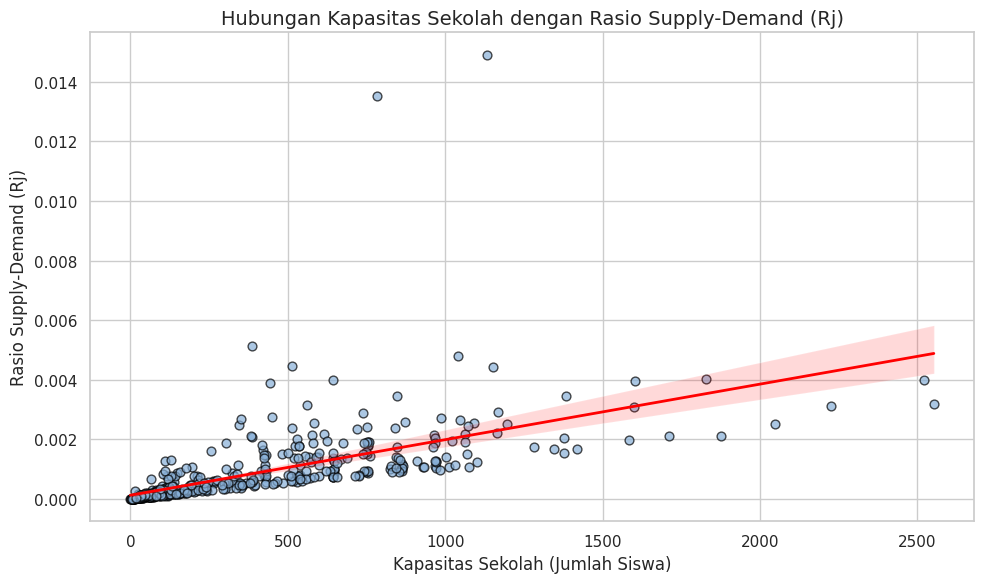


Berikut adalah 5 baris pertama dari gabungan data kapasitas dan rasio Rj:


,Sekolah,Kapasitas,Rj_Ratio
0,SMA 17 BANTUL,19,0.000023
1,SMA 17 I Yogyakarta,15,0.000018
2,SMA ALI MAKSUM,243,0.000254
3,SMA BAITUL QUR`AN YOGYAKARTA,140,0.000585
4,SMA BINA ANAK SHOLEH,52,0.000057


Median Rj_Ratio: 0.0004


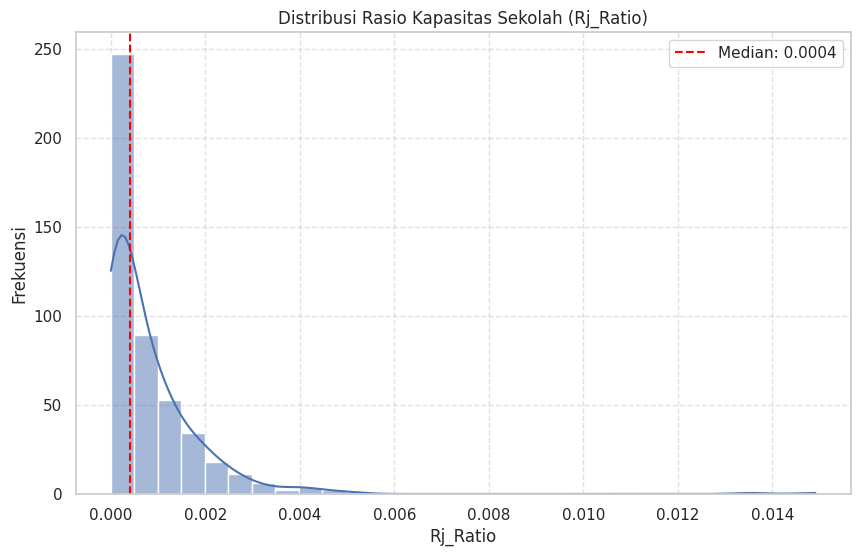

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Memuat Data
file_kapasitas = '/content/drive/MyDrive/bahan_skripsi/data/kapasitas.csv'
df_kapasitas = pd.read_csv(file_kapasitas)
file_rj = '/content/drive/MyDrive/bahan_skripsi/data/Rj_Ratios.csv' # Sesuaikan path-nya jika ada di Google Drive
df_rj = pd.read_csv(file_rj)

# 2. Menggabungkan Data
df_kapasitas_rj = pd.merge(df_kapasitas, df_rj, on='Sekolah', how='inner')

# 3. Membuat Scatter Plot dengan Garis Tren Lurus
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

sns.regplot(
    data=df_kapasitas_rj,
    x='Kapasitas',
    y='Rj_Ratio',
    scatter_kws={'color': '#88b0d8', 'alpha': 0.7, 'edgecolor': 'black', 's': 40},
    line_kws={'color': 'red', 'linewidth': 2} # Garis tren berwarna merah
)

# Menambahkan judul dan label
plt.title('Hubungan Kapasitas Sekolah dengan Rasio Supply-Demand (Rj)', fontsize=14)
plt.xlabel('Kapasitas Sekolah (Jumlah Siswa)', fontsize=12)
plt.ylabel('Rasio Supply-Demand (Rj)', fontsize=12)

plt.tight_layout()
plt.show()

# Menampilkan Preview Data
print("\nBerikut adalah 5 baris pertama dari gabungan data kapasitas dan rasio Rj:")
display(df_kapasitas_rj.head())

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Memuat data
df = pd.read_csv("/content/drive/MyDrive/bahan_skripsi/data/Rj_Ratios.csv")

# Menghitung median
median_val = df['Rj_Ratio'].median()
print(f"Median Rj_Ratio: {median_val:.4f}")

# Membuat histogram untuk distribusi Rj_Ratio
plt.figure(figsize=(10, 6))
sns.histplot(df['Rj_Ratio'], bins=30, kde=True)
plt.axvline(median_val, color='red', linestyle='--', label=f'Median: {median_val:.4f}')
plt.title('Distribusi Rasio Kapasitas Sekolah (Rj_Ratio)')
plt.xlabel('Rj_Ratio')
plt.ylabel('Frekuensi')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

## Menghitung indeks aksesibilitas

In [ ]:
print("Menjalankan Step 2: Menghitung Indeks Aksesibilitas per Desa")

def get_accessibility(row):
    score = 0
    for sekolah in sekolah_list:
        weight_val = row.get(f'W_{sekolah}', 0)
        score += rj_values.get(sekolah, 0) * weight_val
    return score

desa_data['Indeks_Aksesibilitas'] = desa_data.apply(get_accessibility, axis=1)
print("Perhitungan Indeks Aksesibilitas selesai.")

Menjalankan Step 2: Menghitung Indeks Aksesibilitas per Desa
Perhitungan Indeks Aksesibilitas selesai.


/tmp/ipykernel_1747/3543517608.py:10: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  desa_data['Indeks_Aksesibilitas'] = desa_data.apply(get_accessibility, axis=1)


# Kesesuaian Lokasi

## Persiapan

In [ ]:
import os
import warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.mask      import mask as rio_mask
from rasterio.transform import from_bounds
from rasterio.features  import rasterize
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from rasterstats import zonal_stats
from shapely.geometry import box
from scipy.stats import spearmanr

warnings.filterwarnings('ignore')

# ============================================================
# 1. PATH FILE & PENGATURAN UMUM
# ============================================================
output_dir = '/content/drive/My Drive/bahan_skripsi/Kesesuaian/output_mcda'

path_batas            = '/content/drive/My Drive/bahan_skripsi/data/BatasDesaNew.shp'
path_populasi         = '/content/drive/My Drive/bahan_skripsi/Kesesuaian/jurnal variabel/idn_pop_2025_DIY_clipped.tif'
path_slope            = '/content/drive/My Drive/bahan_skripsi/Kesesuaian/jurnal variabel/slope_srtm_diy_deg.tif'
path_elevation        = '/content/drive/My Drive/bahan_skripsi/Kesesuaian/jurnal variabel/elevation_srtm_diy_m.tif'
path_ndvi             = '/content/drive/My Drive/bahan_skripsi/Kesesuaian/jurnal variabel/ndvi_s2_diy_2025.tif'
path_jarak_sungai     = '/content/drive/My Drive/bahan_skripsi/Kesesuaian/jurnal variabel/jarak_sungai_grid500_raster.tif'
path_jarak_kebisingan = '/content/drive/My Drive/bahan_skripsi/Kesesuaian/jurnal variabel/jarak_kebisingan_grid500_raster.tif'
path_jalan            = '/content/drive/My Drive/bahan_skripsi/Kesesuaian/jurnal variabel/panjang_jalan_grid500.tif'

grid_size_m = 500
epsg_utm    = 32749
epsg_geo    = 4326

criteria_type = {
    'populasi'         : 'benefit',
    'slope'            : 'cost',
    'elevation'        : 'cost',
    'ndvi'             : 'benefit',
    'jarak_sungai'     : 'benefit',
    'jarak_kebisingan' : 'benefit',
    'jalan'            : 'benefit',
}

labels = {
    'populasi'         : 'Populasi Penduduk',
    'slope'            : 'Kemiringan Lahan',
    'elevation'        : 'Ketinggian',
    'ndvi'             : 'NDVI',
    'jarak_sungai'     : 'Jarak Sungai',
    'jarak_kebisingan' : 'Jarak Kebisingan',
    'jalan'            : 'Panjang Jalan',
}

# 5 Kelas Kesesuaian
class_labels = ['Sangat Rendah', 'Rendah', 'Sedang', 'Tinggi', 'Sangat Tinggi']
class_colors = ['#d7191c',       '#fdae61', '#ffffbf', '#a6d96a', '#1a9641']


# ============================================================
# 2. SETUP AWAL
# ============================================================
def setup():
    os.makedirs(output_dir, exist_ok=True)
    print("=" * 70)
    print("  ANALISIS KESESUAIAN LOKASI SMA/SEDERAJAT")
    print("  Entropy Weighting + 3 Metode MCDA: WSM | WPM | TOPSIS")
    print("  Klasifikasi: Natural Breaks (Jenks) — 5 Kelas")
    print("  Grid 500×500 m  |  Variabel: 9")
    print("=" * 70)
    print(f"\n  Output dir : {output_dir}")
    print("\n  Cek ketersediaan file:")
    files = [
        ('Batas',             path_batas),
        ('populasi',          path_populasi),
        ('slope',             path_slope),
        ('elevation',         path_elevation),
        ('ndvi',              path_ndvi),
        ('jarak_sungai',      path_jarak_sungai),
        ('jarak_kebisingan',  path_jarak_kebisingan),
        ('jalan',             path_jalan),
    ]
    all_ok = True
    for lbl, p in files:
        ok = os.path.exists(p)
        if not ok:
            all_ok = False
        print(f"    [{'✓' if ok else '✗ TIDAK ADA'}] {lbl}: {os.path.basename(p)}")
    if not all_ok:
        print("\n  [!] Beberapa file tidak ditemukan.")
    print()


# ============================================================
# 3. LOAD BATAS WILAYAH
# ============================================================
def load_boundary():
    gdf = gpd.read_file(path_batas)
    if gdf.crs is None:
        gdf = gdf.set_crs(epsg=epsg_geo)
    gdf_utm = gdf.to_crs(epsg=epsg_utm)
    print(f"\n[1] Batas wilayah: {len(gdf_utm)} fitur | EPSG:{epsg_utm}")
    return gdf_utm


# ============================================================
# 4. LOAD SEMUA RASTER
# ============================================================
def load_rasters(boundary_utm):
    sources = {
        'populasi'         : path_populasi,
        'slope'            : path_slope,
        'elevation'        : path_elevation,
        'ndvi'             : path_ndvi,
        'jarak_sungai'     : path_jarak_sungai,
        'jarak_kebisingan' : path_jarak_kebisingan,
        'jalan'            : path_jalan,
    }
    rasters = {}
    for var, fpath in sources.items():
        if not os.path.exists(fpath):
            print(f"    [!] Tidak ditemukan: {fpath}")
            continue
        with rasterio.open(fpath) as src:
            bnd  = boundary_utm.to_crs(src.crs)
            geom = [bnd.geometry.union_all()]
            data, transform = rio_mask(src, geom, crop=True)
            nd  = src.nodata if src.nodata is not None else -9999
            arr = data[0].astype(float)
            arr[arr == nd] = np.nan
            arr[(arr > 1e10) | (arr < -1e10)] = np.nan
            arr[~np.isfinite(arr)] = np.nan
            rasters[var] = {'data': arr, 'transform': transform, 'crs': src.crs}
            pct = np.sum(~np.isnan(arr)) / arr.size * 100
    return rasters


## Membuat Grid 500 x 500 m

In [ ]:
# ============================================================
# 5. GRID 500 × 500 m
# ============================================================
def create_grid(boundary_utm):
    gs    = grid_size_m
    bbox  = boundary_utm.total_bounds
    union = boundary_utm.geometry.union_all()
    xs    = np.arange(bbox[0], bbox[2], gs)
    ys    = np.arange(bbox[1], bbox[3], gs)
    cells = [box(x, y, x+gs, y+gs)
             for x in xs for y in ys
             if box(x, y, x+gs, y+gs).intersects(union)]
    grid  = gpd.GeoDataFrame(
        {'grid_id': range(len(cells))}, geometry=cells,
        crs=f'EPSG:{epsg_utm}'
    )
    grid['cx'] = grid.geometry.centroid.x
    grid['cy'] = grid.geometry.centroid.y
    print(f"\n[2] Grid {gs}×{gs} m: {len(grid)} sel")
    return grid

## Zonal Statistics

In [ ]:
# ============================================================
# 6. ZONAL STATISTICS
# ============================================================

def extract_zonal(grid, rasters):
    print("\n[3] Zonal Statistics → nilai per sel grid...")
    for var, info in rasters.items():
        tmp = f"/tmp/_z_{var}.tif"
        h, w = info['data'].shape


        with rasterio.open(tmp, 'w', driver='GTiff', height=h, width=w,

                           count=1, dtype='float32', crs=info['crs'],

                           transform=info['transform'], nodata=np.nan) as dst:

            dst.write(info['data'].astype('float32'), 1)


        stats = zonal_stats(grid.to_crs(info['crs']), tmp,
                            stats=['mean'], nodata=np.nan)
        grid[var] = [s['mean'] for s in stats]
        ok = grid[var].notna().sum()
        print(f"    ✓ {var:22s} | valid: {ok}/{len(grid)} sel")
    grid = grid.dropna(subset=list(rasters.keys()), how='all').reset_index(drop=True)
    return grid

## Preprosessing

In [ ]:
# ============================================================
# 6.5 IMPUTASI
# ============================================================
def clean_and_impute(grid, vars_list):
    print("\n[4] Imputasi Nilai Kosong (NaN)...")
    for var in ['populasi']:
        if var in vars_list:
            n = grid[var].isna().sum()
            grid[var] = grid[var].fillna(0)
            print(f"    ✓ {var:22s} | {n} NaN → 0")
    for var in ['slope', 'elevation', 'ndvi',
                'jalan', 'jarak_sungai', 'jarak_kebisingan']:
        if var in vars_list:
            n  = grid[var].isna().sum()
            mv = grid[var].mean()
            grid[var] = grid[var].fillna(mv)
            print(f"    ✓ {var:22s} | {n} NaN → mean ({mv:.2f})")
    return grid


# ============================================================
# 7. NORMALISASI MIN-MAX
# ============================================================
def normalize(grid, vars_list):
    print("\n[5] Normalisasi Min-Max [0.01 – 1.00]...")
    rows = []
    for var in vars_list:
        col = grid[var].dropna()

        if var in ['populasi', 'jalan', 'jarak_sungai', 'jarak_kebisingan', 'elevation','slope','ndvi']:
            col_calc = np.log1p(col)
        else:
            col_calc = col.copy()

        vmin = np.percentile(col_calc, 1)
        vmax = np.percentile(col_calc, 99)
        rng  = vmax - vmin
        if rng == 0:
            vmin, vmax = col_calc.min(), col_calc.max()
            rng = vmax - vmin

        col_clipped = np.clip(col_calc, vmin, vmax)
        ctype = criteria_type[var]

        if rng == 0:
            grid[f'{var}_norm'] = 0.01
        elif ctype == 'benefit':
            grid[f'{var}_norm'] = ((col_clipped - vmin) / rng) * 0.99 + 0.01
        else:
            grid[f'{var}_norm'] = ((vmax - col_clipped) / rng) * 0.99 + 0.01

        nm = grid[f'{var}_norm']
        rows.append({
            'Variabel' : labels[var],
            'Tipe'     : ctype,
            'Min Asal' : round(col.min(), 5),
            'Max Asal' : round(col.max(), 5),
            'Mean Norm': round(nm.mean(), 4),
            'Std Norm' : round(nm.std(),  4),
        })
        print(f"    ✓ {var:22s} | {ctype:7s} | "
              f"[{col.min():.3f} – {col.max():.3f}] → mean_norm={nm.mean():.3f}")

    return grid, pd.DataFrame(rows)

## Pembobotan Entropy

In [ ]:
# ============================================================
# 8. PEMBOBOTAN ENTROPY
# ============================================================
def entropy_weighting(grid, vars_list):
    print("\n[6] Pembobotan Entropy...")
    mat     = grid[[f'{v}_norm' for v in vars_list]].values
    n       = mat.shape[0]
    col_sum = mat.sum(axis=0)
    P       = mat / col_sum
    E       = np.clip(-(1 / np.log(n)) * (P * np.log(P)).sum(axis=0), 0, 1)
    D       = 1 - E
    W       = D / D.sum()
    weights = {v: W[i] for i, v in enumerate(vars_list)}

    rows = []
    for i, v in enumerate(vars_list):
        rows.append({
            'No'               : i + 1,
            'Variabel'         : labels[v],
            'Kode'             : v,
            'Tipe'             : criteria_type[v],
            'Entropy (Ej)'     : round(float(E[i]), 6),
            'Diversifikasi(dj)': round(float(D[i]), 6),
            'Bobot (wj)'       : round(float(W[i]), 6),
            'Bobot (%)'        : round(float(W[i]) * 100, 3),
        })
    df = (pd.DataFrame(rows)
            .sort_values('Bobot (%)', ascending=False)
            .reset_index(drop=True))
    df['Rank'] = df.index + 1

    print(f"\n    ┌{'─'*4}┬{'─'*32}┬{'─'*9}┬{'─'*12}┬{'─'*11}┬{'─'*9}┐")
    print(f"    │ {'No':>2} │ {'Variabel':<30} │ {'Tipe':>7} │ {'Entropy(Ej)':>10} │ {'dj':>9} │ {'Bobot%':>7} │")
    print(f"    ├{'─'*4}┼{'─'*32}┼{'─'*9}┼{'─'*12}┼{'─'*11}┼{'─'*9}┤")
    for _, r in df.iterrows():
        print(f"    │ {int(r['Rank']):>2} │ {r['Variabel']:<30} │ "
              f"{r['Tipe']:>7} │ {r['Entropy (Ej)']:>10.6f} │ "
              f"{r['Diversifikasi(dj)']:>9.6f} │ {r['Bobot (%)']:>6.3f}% │")
    print(f"    ├{'─'*4}┴{'─'*32}┴{'─'*9}┴{'─'*12}┴{'─'*11}┼{'─'*9}┤")
    print(f"    │ {'TOTAL':>58} │ {100.000:>6.3f}% │")
    print(f"    └{'─'*59}┴{'─'*9}┘")
    return weights, df

## Perhitungan MCDA

In [ ]:
# ============================================================
# 9. METODE MCDA
# ============================================================

def wsm_scoring(grid, vars_list, weights):
    print("\n[7a] WSM — Weighted Sum Model...")
    grid['skor_wsm'] = sum(
        weights[v] * grid[f'{v}_norm'].fillna(0.01) for v in vars_list
    )
    _print_score_stats(grid['skor_wsm'], 'WSM')
    return grid


def wpm_scoring(grid, vars_list, weights):
    print("\n[7b] WPM — Weighted Product Model...")
    mat = np.column_stack([
        np.clip(grid[f'{v}_norm'].fillna(0.01).values, 1e-6, None)
        for v in vars_list
    ])
    w_arr   = np.array([weights[v] for v in vars_list])
    log_mat = np.log(mat)
    grid['skor_wpm'] = np.exp((log_mat * w_arr).sum(axis=1))
    _print_score_stats(grid['skor_wpm'], 'WPM')
    return grid


def topsis_scoring(grid, vars_list, weights):
    print("\n[7c] TOPSIS...")
    mat   = np.column_stack([
        grid[f'{v}_norm'].fillna(0.01).values for v in vars_list
    ])
    w_arr = np.array([weights[v] for v in vars_list])
    v_mat = mat * w_arr
    A_pos = v_mat.max(axis=0)
    A_neg = v_mat.min(axis=0)
    d_pos = np.sqrt(((v_mat - A_pos) ** 2).sum(axis=1))
    d_neg = np.sqrt(((v_mat - A_neg) ** 2).sum(axis=1))
    denom = d_pos + d_neg
    denom[denom == 0] = 1e-10
    grid['skor_topsis'] = d_neg / denom
    _print_score_stats(grid['skor_topsis'], 'TOPSIS')
    return grid


def _print_score_stats(s, name):
    print(f"    Min   : {s.min():.4f}")
    print(f"    Max   : {s.max():.4f}")
    print(f"    Mean  : {s.mean():.4f}")
    print(f"    Std   : {s.std():.4f}")
    print(f"    Median: {s.median():.4f}")

## Klasifikasi Natural Breaks

In [ ]:
# ============================================================
# 10. NATURAL BREAKS (JENKS)
# ============================================================
def natural_breaks(values, n_classes=5):
    v = np.sort(values[~np.isnan(values)])
    n = len(v)

    if n == 0:
        raise ValueError("Tidak ada data valid untuk natural_breaks.")
    if n < n_classes:
        unique_vals = np.unique(v)
        breaks = np.linspace(v.min(), v.max(), n_classes + 1)
        breaks[0]  = v.min() - 1e-10
        breaks[-1] = v.max() + 1e-10
        return breaks

    mat1 = np.zeros((n + 1, n_classes + 1), dtype=int)
    mat2 = np.full((n + 1, n_classes + 1), np.inf)
    mat1[1, 1] = 1
    mat2[1, 1] = 0.0

    for l in range(2, n + 1):
        s1  = 0.0
        s2  = 0.0
        w   = 0.0
        for m in range(1, l + 1):
            i3  = l - m + 1
            val = v[i3 - 1]
            w  += 1.0
            s2 += val * val
            s1 += val
            var = s2 - (s1 * s1) / w
            i4  = i3 - 1
            if i4 != 0:
                for j in range(2, n_classes + 1):
                    if mat2[l, j] >= (var + mat2[i4, j - 1]):
                        mat1[l, j] = i3
                        mat2[l, j] = var + mat2[i4, j - 1]
        mat1[l, 1] = 1
        mat2[l, 1] = s2 - (s1 * s1) / w

    # ── Backtracking — hasilkan indeks 1-based ──
    k      = n
    kclass = [0] * (n_classes + 1)
    kclass[n_classes] = n            # batas atas = elemen terakhir (1-based = n)

    for j in range(n_classes, 1, -1):
        id_val      = int(mat1[k, j])
        kclass[j-1] = id_val
        k           = id_val - 1     # lanjut backtrack; k bisa = 0 → hentikan loop

    # ── Konversi indeks 1-based ke nilai aktual ──
    breaks = np.empty(n_classes + 1)
    for i in range(n_classes + 1):
        idx_0based = kclass[i] - 1                  # konversi 1-based → 0-based
        idx_safe   = int(np.clip(idx_0based, 0, n - 1))  # clamp supaya tidak OOB
        breaks[i]  = v[idx_safe]

    breaks[0]  = v.min() - 1e-10    # batas bawah sedikit di bawah minimum
    breaks[-1] = v.max() + 1e-10    # batas atas sedikit di atas maksimum
    return breaks


# ============================================================
# 11. KLASIFIKASI KESESUAIAN — Natural Breaks, 5 Kelas
# ============================================================
def classify_all(grid):
    print("\n[8] Klasifikasi Natural Breaks (Jenks) — 5 Kelas per Metode...")
    n_kelas = len(class_labels)
    breaks  = {}

    for method in ['wsm', 'wpm', 'topsis']:
        col  = f'skor_{method}'
        vals = grid[col].dropna().values

        brk = natural_breaks(vals, n_classes=n_kelas)
        breaks[method] = brk

        grid[f'kelas_{method}'] = pd.cut(
            grid[col], bins=brk, labels=class_labels, include_lowest=True
        )
        grid[f'kelas_id_{method}'] = pd.cut(
            grid[col], bins=brk, labels=[1, 2, 3, 4, 5], include_lowest=True
        ).astype(float)

        total = len(grid)
        ga    = grid_size_m ** 2 / 1e6
        print(f"\n    ─── {method.upper()} | breaks: "
              f"{[f'{b:.4f}' for b in brk]} ───")
        for lbl in class_labels:
            n    = (grid[f'kelas_{method}'] == lbl).sum()
            pct  = n / total * 100
            luas = n * ga
            print(f"    {lbl:<15} {n:>6} sel | {luas:>8.2f} km² | {pct:>5.1f}%")

    return grid, breaks

## Pemilihan Metode

In [ ]:
from sklearn.metrics import roc_auc_score, roc_curve
PATH_SEKOLAH = '/content/drive/My Drive/bahan_skripsi/data/sekolah_eksisting_diy.shp'


# ============================================================
# 12. PEMILIHAN METODE TERBAIK — ROC-AUC terhadap sekolah eksisting
# ============================================================
def select_best_method(grid, path_sekolah=PATH_SEKOLAH, n_boot=300, seed=42):
    print("\n" + "=" * 70)
    print("  PEMILIHAN METODE TERBAIK — ROC-AUC (sekolah eksisting)")
    print("=" * 70)

    methods = ['wsm', 'wpm', 'topsis']
    desc = {'wsm': 'Weighted Sum Model (SAW)',
            'wpm': 'Weighted Product Model',
            'topsis': 'TOPSIS'}
    scores = {m: grid[f'skor_{m}'].values for m in methods}

    # ---------- (a) Spearman antar metode: ukuran pendukung ----------
    pair_corr = {}
    for a, b in [('wsm', 'wpm'), ('wsm', 'topsis'), ('wpm', 'topsis')]:
        rho, _ = spearmanr(scores[a], scores[b])
        pair_corr[(a, b)] = pair_corr[(b, a)] = rho
    avg_rho = {m: np.mean([pair_corr[(m, o)] for o in methods if o != m])
               for m in methods}

    print("\n  Spearman antar metode (pendukung):")
    for a, b in [('wsm', 'wpm'), ('wsm', 'topsis'), ('wpm', 'topsis')]:
        print(f"    {a.upper()} vs {b.upper():<8} ρ = {pair_corr[(a, b)]:.4f}")

    # ---------- (b) Label sel: 1 jika ada >= 1 sekolah ----------
    sekolah = gpd.read_file(path_sekolah)
    if sekolah.crs != grid.crs:
        sekolah = sekolah.to_crs(grid.crs)
    join = gpd.sjoin(sekolah[['geometry']], grid[['geometry']],
                     predicate='within', how='inner')
    y = grid.index.isin(join['index_right']).astype(int)
    pos_idx, neg_idx = np.where(y == 1)[0], np.where(y == 0)[0]
    print(f"\n  Sel dengan sekolah: {len(pos_idx)} dari {len(y)} sel "
          f"({len(pos_idx)/len(y)*100:.2f}%)")

    # Cadangan: tanpa sel positif, AUC tidak bisa dihitung
    if len(pos_idx) == 0:
        print("  ⚠ Tidak ada sekolah di dalam sel grid. Kembali ke pemilihan Spearman.")
        best_method = max(avg_rho, key=avg_rho.get)
        grid['skor_final']  = grid[f'skor_{best_method}']
        grid['kelas_final'] = grid[f'kelas_{best_method}']
        corr_df = pd.DataFrame({'Metode': [m.upper() for m in methods],
                                'Rata2_SpearmanRho': [round(avg_rho[m], 4) for m in methods]})
        return best_method, corr_df, avg_rho, pair_corr
    if len(pos_idx) < 30:
        print("  ⚠ Sel positif sangat sedikit, AUC kurang stabil.")

    # ---------- (c) AUC + bootstrap berpasangan ----------
    auc = {m: roc_auc_score(y, scores[m]) for m in methods}

    rng = np.random.default_rng(seed)
    boot = {m: np.empty(n_boot) for m in methods}
    for b in range(n_boot):
        idx = np.concatenate([rng.choice(pos_idx, len(pos_idx)),
                              rng.choice(neg_idx, len(neg_idx))])
        for m in methods:
            boot[m][b] = roc_auc_score(y[idx], scores[m][idx])

    best_method = max(auc, key=auc.get)

    rows = []
    for m in methods:
        lo, hi = np.percentile(boot[m], [2.5, 97.5])
        if m == best_method:
            beda = '-'
        else:
            d_lo, _ = np.percentile(boot[best_method] - boot[m], [2.5, 97.5])
            beda = 'Ya' if d_lo > 0 else 'Tidak'
        rows.append({
            'Metode'           : m.upper(),
            'Deskripsi'        : desc[m],
            'AUC'              : round(auc[m], 4),
            'CI95_bawah'       : round(lo, 4),
            'CI95_atas'        : round(hi, 4),
            'Beda_vs_terbaik_signifikan': beda,
            'Rata2_SpearmanRho': round(avg_rho[m], 4),
            'Terpilih'         : '★ YA' if m == best_method else 'Tidak',
        })
    corr_df = (pd.DataFrame(rows).sort_values('AUC', ascending=False)
                 .reset_index(drop=True))
    corr_df['Rank_AUC'] = corr_df.index + 1

    print("\n  Hasil AUC:")
    print(corr_df[['Metode', 'AUC', 'CI95_bawah', 'CI95_atas',
                   'Beda_vs_terbaik_signifikan', 'Rata2_SpearmanRho',
                   'Terpilih']].to_string(index=False))

    for m in methods:
        if auc[m] < 0.5:
            print(f"  ⚠ {m.upper()} AUC < 0.5, cek arah cost/benefit variabel.")
    setara = [r['Metode'] for _, r in corr_df.iterrows()
              if r['Beda_vs_terbaik_signifikan'] == 'Tidak']
    if setara:
        print(f"  ℹ Setara secara statistik dengan {best_method.upper()}: "
              f"{', '.join(setara)} (selisih AUC tidak signifikan).")

    print(f"\n  ★ METODE TERPILIH : {best_method.upper()}")
    print(f"  ★ AUC             : {auc[best_method]:.4f}")
    print("=" * 70)

    grid['skor_final']  = grid[f'skor_{best_method}']
    grid['kelas_final'] = grid[f'kelas_{best_method}']

    # ---------- (d) Kurva ROC gabungan ----------
    plt.figure(figsize=(8, 6))
    for m in methods:
        fpr, tpr, _ = roc_curve(y, scores[m])
        plt.plot(fpr, tpr, lw=2, label=f'{m.upper()} (AUC = {auc[m]:.3f})')
    plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
    plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
    plt.title('ROC Curve: WSM vs WPM vs TOPSIS')
    plt.legend(loc='lower right'); plt.grid(True)
    plt.savefig(os.path.join(output_dir, 'roc_curve_3metode.png'),
                dpi=180, bbox_inches='tight')
    plt.close()
    print("    ✓ roc_curve_3metode.png")

    return best_method, corr_df, avg_rho, pair_corr

## Kesesuaian setiap desa

In [ ]:
# ============================================================
# 13. AGREGASI TINGKAT DESA
# ============================================================
def aggregate_to_desa(grid, boundary_utm, best_method):
    print(f"\n[11] Agregasi Area-Weighted per Desa "
          f"(skor metode: {best_method.upper()})...")

    boundary_utm = boundary_utm.copy()
    boundary_utm['desa_idx'] = boundary_utm.index

    skor_col   = f'skor_{best_method}'
    grid_clean = grid.dropna(subset=[skor_col]).copy()

    print("    Memotong grid mengikuti batas desa ")
    intersected = gpd.overlay(grid_clean, boundary_utm, how='intersection')
    intersected['luas_irisan']   = intersected.geometry.area
    intersected['skor_berbobot'] = intersected[skor_col] * intersected['luas_irisan']

    agg_data = intersected.groupby('desa_idx').agg(
        total_skor_berbobot=('skor_berbobot', 'sum'),
        total_luas_grid    =('luas_irisan',   'sum'),
    ).reset_index()
    agg_data['skor_desa'] = (
        agg_data['total_skor_berbobot'] / agg_data['total_luas_grid']
    )

    desa_gdf = boundary_utm.merge(
        agg_data[['desa_idx', 'skor_desa']], on='desa_idx', how='left'
    )
    desa_gdf['skor_desa'] = desa_gdf['skor_desa'].fillna(0)

    desa_vals = desa_gdf['skor_desa'].values
    desa_brk  = natural_breaks(desa_vals, n_classes=len(class_labels))

    desa_gdf['kelas_desa'] = pd.cut(
        desa_gdf['skor_desa'],
        bins=desa_brk,
        labels=class_labels,
        include_lowest=True
    )
    desa_gdf['kelas_id_desa'] = pd.cut(
        desa_gdf['skor_desa'],
        bins=desa_brk,
        labels=[1, 2, 3, 4, 5],
        include_lowest=True
    ).astype(float)

    s = desa_gdf['skor_desa']
    print(f"    Min Skor Desa : {s.min():.4f}")
    print(f"    Max Skor Desa : {s.max():.4f}")
    print(f"    Mean Skor Desa: {s.mean():.4f}")
    print(f"    Natural Breaks: {[f'{b:.4f}' for b in desa_brk]}")

    total_desa = len(desa_gdf)
    print("\n    ╔" + "═" * 57 + "╗")
    print("    ║        DISTRIBUSI KESESUAIAN TINGKAT DESA           ║")
    print("    ╠" + "═" * 17 + "╦" + "═" * 16 + "╦" + "═" * 22 + "╣")
    print("    ║ Kelas           ║ Jumlah Desa    ║ Persentase (%)       ║")
    print("    ╠" + "═" * 17 + "╩" + "═" * 16 + "╩" + "═" * 22 + "╣")
    for lbl in class_labels:
        n   = (desa_gdf['kelas_desa'] == lbl).sum()
        pct = n / total_desa * 100 if total_desa > 0 else 0
        bar = '█' * int(pct / 5)
        print(f"    ║ {lbl:<15} ║ {n:>14} ║ {pct:>8.1f}% {bar:<10} ║")
    print("    ╚" + "═" * 17 + "╩" + "═" * 16 + "╩" + "═" * 22 + "╝")

    return desa_gdf, desa_brk

## Output

In [ ]:
# ============================================================
# 14. EXPORT OUTPUT
# ============================================================
def export_outputs(grid, entropy_df, stats_df, vars_list,
                   best_method, corr_df, breaks, desa_gdf):
    print(f"\n[12] Ekspor ke '{output_dir}'...")

    keep_base  = ['grid_id', 'cx', 'cy'] + vars_list + [f'{v}_norm' for v in vars_list]
    keep_skor  = ['skor_wsm', 'skor_wpm', 'skor_topsis', 'skor_final']
    keep_kelas = ['kelas_wsm', 'kelas_wpm', 'kelas_topsis', 'kelas_final',
                  'kelas_id_wsm', 'kelas_id_wpm', 'kelas_id_topsis']
    keep_all   = keep_base + keep_skor + keep_kelas + ['geometry']
    keep_all   = [c for c in keep_all if c in grid.columns]

    gj = os.path.join(output_dir, 'grid_kesesuaian_sma.geojson')
    grid[keep_all].to_file(gj, driver='GeoJSON')
    print(f"    ✓ GeoJSON grid           : {gj}")

    shp = os.path.join(output_dir, 'grid_kesesuaian_sma.shp')
    grid[keep_all].to_file(shp, driver='ESRI Shapefile')
    print(f"    ✓ Shapefile grid         : {shp}")

    csv_g = os.path.join(output_dir, 'tabel_grid_kesesuaian.csv')
    grid[[c for c in keep_all if c != 'geometry']].to_csv(
        csv_g, index=False, float_format='%.6f')
    print(f"    ✓ CSV grid               : {csv_g}")

    desa_keep = [c for c in desa_gdf.columns
                 if c not in ['desa_idx'] or c == 'geometry']
    desa_gj  = os.path.join(output_dir, 'desa_kesesuaian_sma.geojson')
    desa_shp = os.path.join(output_dir, 'desa_kesesuaian_sma.shp')
    desa_csv = os.path.join(output_dir, 'tabel_desa_kesesuaian.csv')
    desa_gdf[desa_keep].to_file(desa_gj, driver='GeoJSON')
    desa_gdf[desa_keep].to_file(desa_shp, driver='ESRI Shapefile')
    desa_gdf[[c for c in desa_keep if c != 'geometry']].to_csv(
        desa_csv, index=False, float_format='%.6f')
    print(f"    ✓ GeoJSON desa           : {desa_gj}")
    print(f"    ✓ Shapefile desa         : {desa_shp}")
    print(f"    ✓ CSV desa               : {desa_csv}")

    entropy_df.to_csv(os.path.join(output_dir, 'bobot_entropy.csv'), index=False)
    stats_df.to_csv(  os.path.join(output_dir, 'statistik_normalisasi.csv'), index=False)
    corr_df.to_csv(   os.path.join(output_dir, 'perbandingan_metode.csv'),   index=False)
    print(f"    ✓ CSV bobot entropy      : bobot_entropy.csv")
    print(f"    ✓ CSV statistik norm     : statistik_normalisasi.csv")
    print(f"    ✓ CSV perbandingan metode: perbandingan_metode.csv")

    ga = grid_size_m ** 2 / 1e6
    summaries = {}
    for method in ['wsm', 'wpm', 'topsis']:
        smr = (grid.groupby(f'kelas_{method}', observed=True)
                   .agg(jumlah_sel=('grid_id', 'count'))
                   .reset_index()
                   .rename(columns={f'kelas_{method}': 'kelas'}))
        smr['luas_km2'] = smr['jumlah_sel'] * ga
        smr['persen']   = smr['jumlah_sel'] / smr['jumlah_sel'].sum() * 100
        smr['metode']   = method.upper()
        summaries[method] = smr
        smr.to_csv(os.path.join(output_dir, f'ringkasan_kelas_{method}.csv'),
                   index=False, float_format='%.3f')
        print(f"    ✓ CSV ringkasan {method.upper():<8}  : ringkasan_kelas_{method}.csv")

    desa_smr = (desa_gdf.groupby('kelas_desa', observed=True)
                        .agg(jumlah_desa=('skor_desa', 'count'))
                        .reset_index())
    desa_smr['persen'] = desa_smr['jumlah_desa'] / desa_smr['jumlah_desa'].sum() * 100
    desa_smr.to_csv(os.path.join(output_dir, 'ringkasan_kelas_desa.csv'),
                    index=False, float_format='%.3f')
    print(f"    ✓ CSV ringkasan desa     : ringkasan_kelas_desa.csv")

    return summaries, desa_smr


# ============================================================
# 15. VISUALISASI
# ============================================================
def visualize(grid, entropy_df, summaries, desa_gdf, desa_smr,
              boundary_utm, vars_list, breaks, best_method, avg_rho,
              pair_corr, desa_brk):
    print("\n[13] Visualisasi...")
    cmap = dict(zip(class_labels, class_colors))

    methods_plot = ['wsm', 'wpm', 'topsis']
    titles_plot  = {
        'wsm'   : 'WSM (Weighted Sum Model)',
        'wpm'   : 'WPM (Weighted Product Model)',
        'topsis': 'TOPSIS',
    }
    fig, axes = plt.subplots(1, 3, figsize=(22, 9))
    for ax, method in zip(axes, methods_plot):
        for lbl, col in cmap.items():
            sub = grid[grid[f'kelas_{method}'] == lbl]
            if not sub.empty:
                sub.plot(ax=ax, color=col, edgecolor='none', alpha=0.85)
        boundary_utm.boundary.plot(ax=ax, color='black', linewidth=0.8)
        star = '★ TERPILIH' if method == best_method else ''
        ax.set_title(
            f'{titles_plot[method]}\n{star}',
            fontsize=10,
            fontweight='bold'  if method == best_method else 'normal',
            color='darkgreen'  if method == best_method else 'black',
        )
        ax.set_xlabel('Easting (m)', fontsize=8)
        ax.set_ylabel('Northing (m)', fontsize=8)
        ax.ticklabel_format(style='sci', axis='both', scilimits=(0, 0))
        smr = summaries[method]
        info_lines = '\n'.join(
            f"{r['kelas']}: {r['luas_km2']:.1f} km² ({r['persen']:.1f}%)"
            for _, r in smr.iterrows()
        )
        ax.text(0.02, 0.98, info_lines, transform=ax.transAxes, fontsize=7,
                va='top', bbox=dict(boxstyle='round', fc='white', alpha=0.85))

    patches = [mpatches.Patch(color=cmap[l], label=l) for l in class_labels]
    fig.legend(handles=patches, title='Kelas Kesesuaian',
               loc='lower center', ncol=5, fontsize=9, title_fontsize=10,
               bbox_to_anchor=(0.5, -0.02))
    fig.suptitle(
        'Perbandingan Peta Kesesuaian Lokasi SMA/Sederajat\n'
        f'WSM vs WPM vs TOPSIS  |  Natural Breaks (Jenks)  |  '
        f'Metode Terpilih: {best_method.upper()}',
        fontsize=12, fontweight='bold', y=1.01,
    )
    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, 'peta_perbandingan_3metode.png'),
                dpi=180, bbox_inches='tight')
    plt.close()
    print("    ✓ peta_perbandingan_3metode.png")

    fig, ax = plt.subplots(figsize=(13, 10))
    for lbl, col in cmap.items():
        sub = grid[grid['kelas_final'] == lbl]
        if not sub.empty:
            sub.plot(ax=ax, color=col, edgecolor='none', alpha=0.85)
    boundary_utm.boundary.plot(ax=ax, color='black', linewidth=1.2)
    patches = [mpatches.Patch(color=cmap[l], label=l) for l in class_labels]
    ax.legend(handles=patches, title='Kelas Kesesuaian',
              loc='lower right', fontsize=10, title_fontsize=11)
    ax.set_title(
        f'Peta Kesesuaian Lokasi SMA/Sederajat (Grid)\n'
        f'Metode: {best_method.upper()}  |  Natural Breaks  |  {grid_size_m}×{grid_size_m} m',
        fontsize=12, fontweight='bold',
    )
    ax.set_xlabel('Easting (m)')
    ax.set_ylabel('Northing (m)')
    ax.ticklabel_format(style='sci', axis='both', scilimits=(0, 0))
    smr_final = summaries[best_method]
    info = '\n'.join(
        f"{r['kelas']}: {r['luas_km2']:.1f} km² ({r['persen']:.1f}%)"
        for _, r in smr_final.iterrows()
    )
    ax.text(0.02, 0.98, info, transform=ax.transAxes, fontsize=8.5,
            va='top', bbox=dict(boxstyle='round', fc='white', alpha=0.85))
    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, 'peta_kesesuaian_grid_terpilih.png'),
                dpi=200, bbox_inches='tight')
    plt.close()
    print("    ✓ peta_kesesuaian_grid_terpilih.png")

    fig, ax = plt.subplots(figsize=(13, 10))
    for lbl, col in cmap.items():
        sub = desa_gdf[desa_gdf['kelas_desa'] == lbl]
        if not sub.empty:
            sub.plot(ax=ax, color=col, edgecolor='white',
                     linewidth=0.4, alpha=0.9)
    boundary_utm.boundary.plot(ax=ax, color='black', linewidth=1.2)
    patches = [mpatches.Patch(color=cmap[l], label=l) for l in class_labels]
    ax.legend(handles=patches, title='Kelas Kesesuaian Desa',
              loc='lower right', fontsize=10, title_fontsize=11)
    ax.set_title(
        f'Peta Kesesuaian Lokasi SMA/Sederajat (Tingkat Desa)\n'
        f'Area-Weighted Average — Metode: {best_method.upper()}  |  Natural Breaks',
        fontsize=12, fontweight='bold',
    )
    ax.set_xlabel('Easting (m)')
    ax.set_ylabel('Northing (m)')
    ax.ticklabel_format(style='sci', axis='both', scilimits=(0, 0))
    total_d = len(desa_gdf)
    info_d  = '\n'.join(
        f"{r['kelas_desa']}: {r['jumlah_desa']} desa ({r['persen']:.1f}%)"
        for _, r in desa_smr.iterrows()
    )
    ax.text(0.02, 0.98, info_d, transform=ax.transAxes, fontsize=8.5,
            va='top', bbox=dict(boxstyle='round', fc='white', alpha=0.85))
    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, 'peta_kesesuaian_desa.png'),
                dpi=200, bbox_inches='tight')
    plt.close()
    print("    ✓ peta_kesesuaian_desa.png")

    fig, axes = plt.subplots(1, 2, figsize=(20, 9))
    for lbl, col in cmap.items():
        sub = grid[grid['kelas_final'] == lbl]
        if not sub.empty:
            sub.plot(ax=axes[0], color=col, edgecolor='none', alpha=0.85)
    boundary_utm.boundary.plot(ax=axes[0], color='black', linewidth=0.8)
    axes[0].set_title(f'Level Grid — {best_method.upper()}', fontweight='bold')
    axes[0].ticklabel_format(style='sci', axis='both', scilimits=(0, 0))

    for lbl, col in cmap.items():
        sub = desa_gdf[desa_gdf['kelas_desa'] == lbl]
        if not sub.empty:
            sub.plot(ax=axes[1], color=col, edgecolor='white',
                     linewidth=0.4, alpha=0.9)
    boundary_utm.boundary.plot(ax=axes[1], color='black', linewidth=0.8)
    axes[1].set_title(f'Level Desa — {best_method.upper()} (Area-Weighted)',
                      fontweight='bold')
    axes[1].ticklabel_format(style='sci', axis='both', scilimits=(0, 0))

    patches = [mpatches.Patch(color=cmap[l], label=l) for l in class_labels]
    fig.legend(handles=patches, title='Kelas Kesesuaian',
               loc='lower center', ncol=5, fontsize=9, title_fontsize=10,
               bbox_to_anchor=(0.5, -0.02))
    fig.suptitle(
        f'Kesesuaian Lokasi SMA/Sederajat — Grid vs Desa\n'
        f'Metode: {best_method.upper()}  |  Natural Breaks (Jenks) 5 Kelas',
        fontsize=13, fontweight='bold', y=1.01,
    )
    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, 'peta_grid_vs_desa.png'),
                dpi=180, bbox_inches='tight')
    plt.close()
    print("    ✓ peta_grid_vs_desa.png")

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    for ax, (ma, mb), c in zip(
        axes,
        [('wsm', 'wpm'), ('wsm', 'topsis')],
        ['#1565C0', '#B71C1C'],
    ):
        ax.scatter(grid[f'skor_{ma}'], grid[f'skor_{mb}'],
                   alpha=0.25, s=4, color=c)
        rho = pair_corr.get((ma, mb), pair_corr.get((mb, ma), 0))
        ax.set_xlabel(f'Skor {ma.upper()}', fontsize=11)
        ax.set_ylabel(f'Skor {mb.upper()}', fontsize=11)
        ax.set_title(f'{ma.upper()} vs {mb.upper()}  (ρ = {rho:.4f})',
                     fontweight='bold')
        ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, 'scatter_perbandingan_metode.png'),
                dpi=150, bbox_inches='tight')
    plt.close()
    print("    ✓ scatter_perbandingan_metode.png")

    methods = ['wsm', 'wpm', 'topsis']
    rho_mat = np.ones((3, 3))
    for i, a in enumerate(methods):
        for j, b in enumerate(methods):
            if i != j:
                rho_mat[i, j] = pair_corr.get((a, b),
                                               pair_corr.get((b, a), 0))
    fig, ax = plt.subplots(figsize=(7, 5))
    sns.heatmap(rho_mat, annot=True, fmt='.4f', cmap='YlGn',
                xticklabels=[m.upper() for m in methods],
                yticklabels=[m.upper() for m in methods],
                vmin=0, vmax=1, ax=ax,
                annot_kws={'size': 13, 'weight': 'bold'},
                linewidths=1, cbar_kws={'shrink': 0.8})
    ax.set_title('Rank Agreement Index\n(Spearman Correlation antar Metode)',
                 fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, 'rank_agreement_heatmap.png'),
                dpi=150, bbox_inches='tight')
    plt.close()
    print("    ✓ rank_agreement_heatmap.png")

    fig, ax = plt.subplots(figsize=(10, 6))
    bar_colors = ['#2196F3' if criteria_type.get(k, 'benefit') == 'benefit'
                  else '#F44336' for k in entropy_df['Kode']]
    bars = ax.barh(entropy_df['Variabel'], entropy_df['Bobot (%)'],
                   color=bar_colors, height=0.6, edgecolor='white', linewidth=0.5)
    for b, v in zip(bars, entropy_df['Bobot (%)']):
        ax.text(v + 0.05, b.get_y() + b.get_height() / 2,
                f'{v:.3f}%', va='center', fontsize=9.5)
    ax.legend(handles=[
        mpatches.Patch(color='#2196F3', label='Benefit'),
        mpatches.Patch(color='#F44336', label='Cost'),
    ], loc='lower right', fontsize=9)
    ax.set_xlabel('Bobot Entropy (%)', fontsize=11)
    ax.set_title('Bobot Entropy — Variabel Kesesuaian Lokasi SMA',
                 fontsize=12, fontweight='bold')
    ax.set_xlim(0, entropy_df['Bobot (%)'].max() * 1.25)
    ax.invert_yaxis()
    ax.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, 'bobot_entropy.png'),
                dpi=150, bbox_inches='tight')
    plt.close()
    print("    ✓ bobot_entropy.png")

    colors_hist = {'wsm': '#4CAF50', 'wpm': '#FF9800', 'topsis': '#9C27B0'}
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    for ax, method in zip(axes, ['wsm', 'wpm', 'topsis']):
        ax.hist(grid[f'skor_{method}'].dropna(), bins=50,
                color=colors_hist[method], edgecolor='white', alpha=0.85)
        for brk in breaks[method][1:-1]:
            ax.axvline(brk, color='black', linestyle='--', linewidth=1)
        star = ' ★ TERPILIH' if method == best_method else ''
        ax.set_title(f'{method.upper()}{star}', fontweight='bold')
        ax.set_xlabel(f'Skor {method.upper()}')
        ax.set_ylabel('Jumlah Sel Grid')
        ax.grid(alpha=0.3)
    plt.suptitle('Distribusi Skor — Garis Putus: Batas Natural Breaks',
                 fontsize=11, fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, 'distribusi_skor_3metode.png'),
                dpi=150, bbox_inches='tight')
    plt.close()
    print("    ✓ distribusi_skor_3metode.png")

    norm_cols = [f'{v}_norm' for v in vars_list]
    rename    = {f'{v}_norm': labels[v] for v in vars_list}
    corr      = grid[norm_cols].rename(columns=rename).corr()
    fig, ax   = plt.subplots(figsize=(10, 8))
    sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool)),
                annot=True, fmt='.2f', cmap='RdYlGn', center=0,
                vmin=-1, vmax=1, linewidths=0.5, ax=ax,
                annot_kws={'size': 9}, cbar_kws={'shrink': 0.8})
    ax.set_title('Korelasi Antar Variabel (setelah normalisasi)',
                 fontsize=12, fontweight='bold')
    ax.tick_params(axis='x', rotation=40, labelsize=9)
    ax.tick_params(axis='y', rotation=0,  labelsize=9)
    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, 'korelasi_variabel.png'),
                dpi=150, bbox_inches='tight')
    plt.close()
    print("    ✓ korelasi_variabel.png")


# ============================================================
# 16. RINGKASAN AKHIR
# ============================================================
def print_final(entropy_df, summaries, desa_smr, best_method, avg_rho):
    print("\n" + "=" * 70)
    print("  RINGKASAN HASIL ANALISIS AKHIR")
    print("=" * 70)

    print("\n📊 Bobot Entropy:")
    for _, r in entropy_df.iterrows():
        bar = '█' * int(r['Bobot (%)'] / 2)
        print(f"   {int(r['Rank'])}.  {r['Variabel']:<30} {r['Bobot (%)']:>6.3f}%  {bar}")

    print("\n🔢 Metode terbaik")
    for m in sorted(avg_rho, key=avg_rho.get, reverse=True):
        star = '  ← TERPILIH ★' if m == best_method else ''
        print(f"   {m.upper():<10} ρ = {avg_rho[m]:.4f}{star}")

    print(f"\n🗺️  Kelas Grid — Metode: {best_method.upper()} (Natural Breaks)")
    for _, r in summaries[best_method].iterrows():
        bar = '█' * int(r['persen'] / 3)
        print(f"   {r['kelas']:<15} {r['luas_km2']:>8.2f} km²  {r['persen']:>5.1f}%  {bar}")

    print(f"\n🏘️  Kelas Desa — {best_method.upper()} Area-Weighted (Natural Breaks)")
    for _, r in desa_smr.iterrows():
        bar = '█' * int(r['persen'] / 3)
        print(f"   {r['kelas_desa']:<15} {r['jumlah_desa']:>5} desa  {r['persen']:>5.1f}%  {bar}")

    print(f"\n📂 Output tersimpan di: '{output_dir}'")
    files = [
        'grid_kesesuaian_sma.geojson         ← QGIS/ArcGIS (semua metode)',
        'grid_kesesuaian_sma.shp             ← shapefile grid',
        'desa_kesesuaian_sma.geojson         ← agregasi per desa',
        'desa_kesesuaian_sma.shp             ← shapefile desa',
        'bobot_entropy.csv',
        'perbandingan_metode.csv             ← rank agreement',
        'tabel_grid_kesesuaian.csv',
        'tabel_desa_kesesuaian.csv',
        'ringkasan_kelas_wsm/wpm/topsis.csv',
        'ringkasan_kelas_desa.csv',
        'peta_perbandingan_3metode.png       ← WSM vs WPM vs TOPSIS',
        'peta_kesesuaian_grid_terpilih.png',
        'peta_kesesuaian_desa.png            ← ★ peta desa',
        'peta_grid_vs_desa.png               ← grid & desa berdampingan',
        'rank_agreement_heatmap.png',
        'scatter_perbandingan_metode.png',
        'distribusi_skor_3metode.png',
        'bobot_entropy.png',
        'korelasi_variabel.png',
    ]
    for f in files:
        print(f"   {f}")
    print("=" * 70)


# ============================================================
# MAIN
# ============================================================
def main():
    setup()

    boundary = load_boundary()
    rasters  = load_rasters(boundary)

    if len(rasters) == 0:
        print("\n[ERROR] Tidak ada raster yang berhasil dimuat.")
        return

    vars_list = list(rasters.keys())
    grid      = create_grid(boundary)
    grid      = extract_zonal(grid, rasters)
    grid      = clean_and_impute(grid, vars_list)
    grid, stats_df  = normalize(grid, vars_list)
    weights, ent_df = entropy_weighting(grid, vars_list)

    grid = wsm_scoring(grid, vars_list, weights)
    grid = wpm_scoring(grid, vars_list, weights)
    grid = topsis_scoring(grid, vars_list, weights)

    grid, breaks = classify_all(grid)

    best_method, corr_df, avg_rho, pair_corr = select_best_method(grid)

    desa_gdf, desa_brk = aggregate_to_desa(grid, boundary, best_method)

    summaries, desa_smr = export_outputs(
        grid, ent_df, stats_df, vars_list,
        best_method, corr_df, breaks, desa_gdf,
    )
    visualize(
        grid, ent_df, summaries, desa_gdf, desa_smr,
        boundary, vars_list, breaks, best_method, avg_rho,
        pair_corr, desa_brk,
    )

    print_final(ent_df, summaries, desa_smr, best_method, avg_rho)


if __name__ == '__main__':
    main()

  ANALISIS KESESUAIAN LOKASI SMA/SEDERAJAT
  Entropy Weighting + 3 Metode MCDA: WSM | WPM | TOPSIS
  Klasifikasi: Natural Breaks (Jenks) — 5 Kelas
  Grid 500×500 m  |  Variabel: 9

  Output dir : /content/drive/My Drive/bahan_skripsi/Kesesuaian/output_mcda

  Cek ketersediaan file:
    [✓] Batas: BatasDesaNew.shp
    [✓] populasi: idn_pop_2025_DIY_clipped.tif
    [✓] slope: slope_srtm_diy_deg.tif
    [✓] elevation: elevation_srtm_diy_m.tif
    [✓] ndvi: ndvi_s2_diy_2025.tif
    [✓] jarak_sungai: jarak_sungai_grid500_raster.tif
    [✓] jarak_kebisingan: jarak_kebisingan_grid500_raster.tif
    [✓] jalan: panjang_jalan_grid500.tif


[1] Batas wilayah: 438 fitur | EPSG:32749

[2] Grid 500×500 m: 13162 sel

[3] Zonal Statistics → nilai per sel grid...
    ✓ populasi               | valid: 11990/13162 sel
    ✓ slope                  | valid: 13162/13162 sel
    ✓ elevation              | valid: 13162/13162 sel
    ✓ ndvi                   | valid: 13162/13162 sel
    ✓ jarak_sungai         

## Peta Kesesuaian

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import os
import geopandas as gpd

output_mcda_dir = '/content/drive/My Drive/bahan_skripsi/Kesesuaian/output_mcda'
path_desa_gdf = os.path.join(output_mcda_dir, 'desa_kesesuaian_sma.shp')
path_boundary = '/content/drive/My Drive/bahan_skripsi/data/BatasDesaNew.shp'

desa_gdf = gpd.read_file(path_desa_gdf)
boundary = gpd.read_file(path_boundary)

if desa_gdf.crs != boundary.crs:
    boundary = boundary.to_crs(desa_gdf.crs)

class_labels = ['Sangat Rendah', 'Rendah', 'Sedang', 'Tinggi', 'Sangat Tinggi']
class_colors = ['#d7191c', '#fdae61', '#ffffbf', '#a6d96a', '#1a9641']
best_method = 'WSM'

cmap = dict(zip(class_labels, class_colors))

desa_brk = [0.3807, 0.4908, 0.5898, 0.6401, 0.7013, 0.7710]

rentang_nilai_formatted = {}
if len(desa_brk) == len(class_labels) + 1:
    for i in range(len(class_labels)):
        lower_bound = f"{desa_brk[i]:.4f}"
        upper_bound = f"{desa_brk[i+1]:.4f}"
        if i == 0:
            rentang_nilai_formatted[class_labels[i]] = f"(0.0000 - {upper_bound})"
        elif i == len(class_labels) - 1:
            rentang_nilai_formatted[class_labels[i]] = f"({lower_bound} - 1.0000)"
        else:
            rentang_nilai_formatted[class_labels[i]] = f"({lower_bound} - {upper_bound})"
else:
    print("Warning: desa_brk does not match class_labels count. Legend ranges will be generic.")
    for i in range(len(class_labels)):
        rentang_nilai_formatted[class_labels[i]] = f"(Range {i+1})"

fig, ax = plt.subplots(figsize=(14, 10), facecolor='white')
ax.set_facecolor('white')

for lbl, col in cmap.items():
    sub = desa_gdf[desa_gdf['kelas_desa'] == lbl]
    if not sub.empty:
        sub.plot(ax=ax, color=col, edgecolor='none', alpha=0.9)

boundary.boundary.plot(ax=ax, color='black', linewidth=0.8, alpha=0.6)

ax.set_axis_off()

map_title = (f'Peta Kesesuaian Lokasi Fasilitas Pendidikan Jenjang SMA/Sederajat (Tingkat Desa)\n' +
             f'Daerah Isntimewa Yogyakarta Tahun 2025')
ax.text(0.01, 0.98,
        map_title,
        transform=ax.transAxes,
        fontsize=14, fontweight='bold', va='top', ha='left')

legend_elements = []
for kat in class_labels:
    range_str = rentang_nilai_formatted.get(kat, "")
    label_text = f"{kat} {range_str}"
    patch = mpatches.Patch(facecolor=cmap[kat], edgecolor='black', linewidth=1, label=label_text)
    legend_elements.append(patch)

leg = ax.legend(
    handles=legend_elements,
    loc='lower left',
    title="Kelas Kesesuaian",
    frameon=True,
    facecolor='white',
    framealpha=1,
    edgecolor='silver',
    bbox_to_anchor=(0.01, 0.02)
)
plt.setp(leg.get_title(), fontweight='bold', fontsize=11)

plt.tight_layout()

output_png = os.path.join(output_mcda_dir, 'Peta_Kesesuaian_Lokasi_Desa_Final.png')
plt.savefig(output_png, dpi=300, bbox_inches='tight', facecolor='white')
plt.close()

print(f"Peta kesesuaian lokasi berhasil disimpan di: {output_png}")

Peta kesesuaian lokasi berhasil disimpan di: /content/drive/My Drive/bahan_skripsi/Kesesuaian/output_mcda/Peta_Kesesuaian_Lokasi_Desa_Final.png


# Titik Sekolah

In [ ]:
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point
import os

# ============================================================
# 1. TENTUKAN PATH FILE
# ============================================================
path_csv = '/content/drive/My Drive/bahan_skripsi/data/datasekolahfix.csv'

# Path untuk menyimpan hasil Shapefile (.shp)
path_shp_output = '/content/drive/My Drive/bahan_skripsi/data/sekolah_eksisting_diy.shp'

# ============================================================
# 2. PROSES KONVERSI CSV KE SHP
# ============================================================
print("Membaca file CSV...")
df_sekolah = pd.read_csv(path_csv)

# Menampilkan nama-nama kolom agar Anda bisa mengeceknya
print(f"Kolom yang tersedia di CSV: {list(df_sekolah.columns)}")

kolom_lon = 'X'
kolom_lat = 'Y'

# Membuat list geometri berupa Titik (Point)
geometri = [Point(xy) for xy in zip(df_sekolah[kolom_lon], df_sekolah[kolom_lat])]

# Mengubah DataFrame Pandas menjadi GeoDataFrame
gdf_sekolah = gpd.GeoDataFrame(df_sekolah, geometry=geometri, crs="EPSG:4326")

# Memproyeksikan dari Derajat (WGS84) ke Meter (UTM Zone 49S)
gdf_sekolah = gdf_sekolah.to_crs(epsg=32749)

# ============================================================
# 3. MENYIMPAN HASIL
# ============================================================
print("\nMenyimpan ke format Shapefile (.shp)...")
os.makedirs(os.path.dirname(path_shp_output), exist_ok=True)
gdf_sekolah.to_file(path_shp_output, driver='ESRI Shapefile')

print(f"Selesai! File Shapefile berhasil dibuat dan disimpan di:\n -> {path_shp_output}")

Membaca file CSV...
Kolom yang tersedia di CSV: ['Nama Satuan Pendidikan', 'X', 'Y', 'kapasitas']

Menyimpan ke format Shapefile (.shp)...
Selesai! File Shapefile berhasil dibuat dan disimpan di:
 -> /content/drive/My Drive/bahan_skripsi/data/sekolah_eksisting_diy.shp


In [ ]:
import os
import warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns

import libpysal
from esda.moran import Moran, Moran_Local
from splot.esda import plot_local_autocorrelation

warnings.filterwarnings('ignore')

# ============================================================
# 0. PENGATURAN PATH DATA
# ============================================================
output_eval_dir = '/content/drive/My Drive/bahan_skripsi/Kesesuaian/output_evaluasi_final'
os.makedirs(output_eval_dir, exist_ok=True)

# Path Evaluasi 1 & 2
path_prioritas = '/content/drive/My Drive/bahan_skripsi/Kesesuaian/output_overlay/Kebijakan_Lokasi_SMA_Desa.shp' # Corrected path
path_sekolah   = '/content/drive/My Drive/bahan_skripsi/data/sekolah_eksisting_diy.shp'

# Path Evaluasi 3 (Uji Sensitivitas) menggunakan CSV Grid dan Batas Desa
path_batas     = '/content/drive/My Drive/bahan_skripsi/data/BatasDesaNew.shp'
path_grid_csv  = '/content/drive/My Drive/bahan_skripsi/Kesesuaian/output_mcda/tabel_grid_kesesuaian.csv'

print("="*60)
print("  MASTER SCRIPT EVALUASI KESESUAIAN & PRIORITAS LOKASI")
print("="*60)
print("\nMemuat data spasial utama...")

try:
    gdf_prioritas = gpd.read_file(path_prioritas)
    gdf_sekolah   = gpd.read_file(path_sekolah)
except Exception as e:
    print(f"[!] Gagal memuat data utama. Pastikan path benar. Error: {e}")
    exit()

# Penyeragaman Proyeksi ke UTM Zone 49S
for gdf in [gdf_prioritas, gdf_sekolah]:
    if gdf.crs is None or gdf.crs.to_epsg() != 32749:
        gdf.to_crs(epsg=32749, inplace=True)


# ============================================================
# FUNGSI BANTUAN: NATURAL BREAKS (JENKS)
# ============================================================
def natural_breaks(values, n_classes=5):
    """Algoritma Jenks Natural Breaks untuk klasifikasi data."""
    v = np.sort(values[~np.isnan(values)])
    n = len(v)

    if n == 0:
        raise ValueError("Tidak ada data valid untuk natural_breaks.")
    if n < n_classes:
        breaks = np.linspace(v.min(), v.max(), n_classes + 1)
        breaks[0]  = v.min() - 1e-10
        breaks[-1] = v.max() + 1e-10
        return breaks

    mat1 = np.zeros((n + 1, n_classes + 1), dtype=int)
    mat2 = np.full((n + 1, n_classes + 1), np.inf)
    mat1[1, 1] = 1
    mat2[1, 1] = 0.0

    for l in range(2, n + 1):
        s1 = 0.0
        s2 = 0.0
        w  = 0.0
        for m in range(1, l + 1):
            i3 = l - m + 1
            val = v[i3 - 1]
            w += 1.0
            s2 += val * val
            s1 += val
            var = s2 - (s1 * s1) / w
            i4 = i3 - 1
            if i4 != 0:
                for j in range(2, n_classes + 1):
                    if mat2[l, j] >= (var + mat2[i4, j - 1]):
                        mat1[l, j] = i3
                        mat2[l, j] = var + mat2[i4, j - 1]
        mat1[l, 1] = 1
        mat2[l, 1] = s2 - (s1 * s1) / w

    k = n
    kclass = [0] * (n_classes + 1)
    kclass[n_classes] = n

    for j in range(n_classes, 1, -1):
        id_val = int(mat1[k, j])
        kclass[j-1] = id_val
        k = id_val - 1

    breaks = np.empty(n_classes + 1)
    for i in range(n_classes + 1):
        idx_0based = kclass[i] - 1
        idx_safe   = int(np.clip(idx_0based, 0, n - 1))
        breaks[i]  = v[idx_safe]

    breaks[0]  = v.min() - 1e-10
    breaks[-1] = v.max() + 1e-10
    return breaks


# ============================================================
# EVALUASI 1: VALIDASI EMPIRIS (GROUND TRUTH)
# ============================================================
def evaluasi_ground_truth(prioritas_gdf, sekolah_gdf):
    print("\n" + "="*50)
    print(" EVALUASI 1: VALIDASI EMPIRIS (Ground Truth)")
    print("="*50)

    kolom_p = 'Kebijakan' if 'Kebijakan' in prioritas_gdf.columns else prioritas_gdf.columns[-1]

    sekolah_di_desa = gpd.sjoin(sekolah_gdf, prioritas_gdf[['geometry', kolom_p]], how='inner', predicate='within')
    distribusi = sekolah_di_desa[kolom_p].value_counts().sort_index()
    total = len(sekolah_di_desa)

    print(f"Total Sekolah Tervalidasi: {total} unit\n")
    for p, jml in distribusi.items():
        print(f" - {p:<30}: {jml:>3} sekolah ({(jml/total)*100:>5.1f}%)")

    plt.figure(figsize=(10, 6))
    sns.barplot(x=distribusi.values, y=distribusi.index, palette='RdYlGn_r', edgecolor='black')
    for index, value in enumerate(distribusi.values):
        plt.text(value + 0.3, index, str(value), color='black', va='center', fontweight='bold')

    plt.title('Validasi Model: Distribusi SMA Eksisting pada Peta Prioritas', fontweight='bold', pad=15)
    plt.xlabel('Jumlah Sekolah')
    plt.ylabel('Kelas Prioritas Rekomendasi')
    plt.tight_layout()
    plt.savefig(os.path.join(output_eval_dir, 'Evaluasi_1_GroundTruth.png'), dpi=200)
    plt.close()
    print("✓ Grafik Validasi Ground Truth disimpan.")


# ============================================================
# EVALUASI 2: AUTOKORELASI SPASIAL (MORAN'S I)
# ============================================================
def evaluasi_moran_prioritas(prioritas_gdf):
    print("\n" + "="*50)
    print(" EVALUASI 2: MORAN'S I (Keadilan & Distribusi Spasial)")
    print("="*50)

    kolom_p = 'Prioritas' if 'Prioritas' in prioritas_gdf.columns else prioritas_gdf.columns[-1]

    dict_skor = {
        'Kebijakan 1 (Pembangunan Sekolah Baru Segera)'  : 5,
        'Kebijakan 3 (Peningkatan Kapasitas Eksisting)'  : 4,
        'Kebijakan 4 (Cadangan Jangka Menengah)'         : 3,
        'Kebijakan 2 (Intervensi Transportasi & Zonasi)' : 2,
        'Kebijakan 5 (Kawasan Pembatas / Status Quo)'    : 1,
        'Tidak Ada Data'                                 : np.nan # Map 'Tidak Ada Data' to NaN for exclusion
    }

    prioritas_gdf['skor_numerik'] = prioritas_gdf[kolom_p].apply(lambda x: dict_skor.get(str(x).strip()))
    desa_bersih = prioritas_gdf.dropna(subset=['skor_numerik']).copy()


    desa_bersih['skor_numerik'] = pd.to_numeric(desa_bersih['skor_numerik'], errors='coerce')
    desa_bersih.dropna(subset=['skor_numerik'], inplace=True)

    if len(desa_bersih) < 2:
        print("[!] Tidak cukup data setelah pembersihan untuk Moran's I. Lewati analisis.")
        return
    if desa_bersih['skor_numerik'].nunique() < 2:
        print("[!] Tidak ada variasi dalam 'skor_numerik' setelah pembersihan. Tidak dapat menghitung Moran's I.")
        print(f"    Nilai unik skor: {np.unique(desa_bersih['skor_numerik'].values)}")
        return

    w = libpysal.weights.Queen.from_dataframe(desa_bersih)
    w.transform = 'r'
    y = desa_bersih['skor_numerik'].values

    if w.is_univariate == False and w.n > 0:
        print("[!] Beberapa observasi terisolasi (tidak ada tetangga) dalam matriks bobot spasial. Ini bisa memengaruhi hasil.")

    mi = Moran(y, w)
    print(f"Global Moran's I Index : {mi.I:.4f} (P-Value: {mi.p_sim:.4f})")

    if np.isnan(mi.I):
        print("[!] Gagal menghitung Global Moran's I. Ini mungkin disebabkan oleh matriks bobot yang degenerasi atau kurangnya variasi data.")
        return

    if mi.I > 0.1 and mi.p_sim <= 0.05:
        print("Kesimpulan: Desa-desa prioritas mengelompok (Clustered)")
    else:
        print("Kesimpulan: Desa-desa prioritas tersebar merata (Dispersed/Random)")

    try:
        lisa = Moran_Local(y, w)
        fig, ax = plot_local_autocorrelation(lisa, desa_bersih, 'skor_numerik')
        fig.set_size_inches(12, 8)
        plt.suptitle('Peta Hotspot & Coldspot Prioritas Lokasi SMA di DIY', fontweight='bold', fontsize=14)
        plt.savefig(os.path.join(output_eval_dir, 'Evaluasi_2_LISA_Prioritas.png'), dpi=200)
        plt.close()
        print("✓ Peta Hotspot LISA disimpan.")
    except Exception as e:
        print(f"[!] Gagal membuat plot LISA. Error: {e}")
        print("    Ini mungkin disebabkan oleh masalah pada matriks bobot, data yang tersisa terlalu sedikit, atau kurangnya variasi.")


# ============================================================
# EVALUASI 3: UJI SENSITIVITAS MCDA (Metode Spatial Join Grid)
# ============================================================
def uji_sensitivitas_mcda(csv_path, batas_path):
    print("\n" + "="*50)
    print(" EVALUASI 3: UJI SENSITIVITAS (Robustness Model MCDA)")
    print("="*50)

    if not os.path.exists(csv_path) or not os.path.exists(batas_path):
        print(f"[!] File tidak ditemukan untuk Uji Sensitivitas.")
        print(f"    Cek kembali: \n    1. {csv_path}\n    2. {batas_path}")
        return

    print("Memproses agregasi nilai kriteria dari Grid ke tingkat Desa...")

    # 1. Load Batas Desa
    gdf_batas = gpd.read_file(batas_path)
    if gdf_batas.crs is None or gdf_batas.crs.to_epsg() != 32749:
        gdf_batas = gdf_batas.to_crs(epsg=32749)
    gdf_batas['id_desa_temp'] = gdf_batas.index # Buat ID unik sementara

    # 2. Load Data Grid & Konversi ke Point Geometry
    df_grid = pd.read_csv(csv_path)
    gdf_grid = gpd.GeoDataFrame(
        df_grid,
        geometry=gpd.points_from_xy(df_grid['cx'], df_grid['cy']),
        crs="EPSG:32749"
    )

    # 3. Spatial Join: Cari titik grid mana yang masuk ke desa mana
    grid_desa = gpd.sjoin(gdf_grid, gdf_batas[['id_desa_temp', 'geometry']], how='inner', predicate='within')

    # 4. Agregasi Rata-rata per Desa
    kriteria_cols = [
        'populasi_norm', 'ndvi_norm', 'lst_norm', 'jalan_norm',
        'jarak_sungai_norm', 'slope_norm',
        'jarak_kebisingan_norm', 'elevation_norm'
    ]

    missing = [c for c in kriteria_cols if c not in df_grid.columns]
    if missing:
        print(f"[!] Kolom kriteria tidak ditemukan di CSV: {missing}")
        return

    desa_kriteria = grid_desa.groupby('id_desa_temp')[kriteria_cols].mean().reset_index()

    # 5. Skenario Pembobotan (Pemetaan Eksplisit)
    scenarios = {
        'Skenario Asli (Entropy)': {
            'populasi_norm': 0.30021, 'ndvi_norm': 0.05530, 'lst_norm': 0.20316,
            'jalan_norm': 0.15249, 'jarak_sungai_norm': 0.10427, 'slope_norm': 0.08394,'jarak_kebisingan_norm': 0.05059, 'elevation_norm': 0.05006
        },
        'Skenario 1 (Equal Weights)': {k: 1/8 for k in kriteria_cols},
        'Skenario 2 (Sosio-Demografis)': {
            'populasi_norm': 0.40, 'ndvi_norm': 0.05, 'lst_norm': 0.05,
            'jalan_norm': 0.30, 'jarak_sungai_norm': 0.05, 'slope_norm': 0.05,
             'jarak_kebisingan_norm': 0.05, 'elevation_norm': 0.05
        }
    }

    df_komparasi = pd.DataFrame({'id_desa_temp': desa_kriteria['id_desa_temp']})
    labels_kelas = ['Kesesuaian Sangat Rendah', 'Kesesuaian Rendah', 'Kesesuaian Sedang', 'Kesesuaian Tinggi', 'Kesesuaian Sangat Tinggi']

    for nama_skenario, bobot_dict in scenarios.items():
        # Hitung SAW Manual per desa
        skor_saw = pd.Series(np.zeros(len(desa_kriteria)))
        for k, w in bobot_dict.items():
            skor_saw += desa_kriteria[k].fillna(0.01) * w

        # Penentuan batas kelas menggunakan Natural Breaks (Jenks)
        breaks = natural_breaks(skor_saw.values, n_classes=5)

        df_komparasi[nama_skenario] = pd.cut(skor_saw, bins=breaks, labels=labels_kelas, include_lowest=True)

    print("\nDistribusi Perubahan Kelas Kesesuaian Berdasarkan Skenario Bobot (Natural Breaks):")
    summary_list = []

    for col in scenarios.keys():
        counts = df_komparasi[col].value_counts().reindex(labels_kelas).fillna(0).astype(int)
        print(f"\n [+] {col}:")
        for kls, jml in counts.items():
            print(f"     - {kls:<25}: {jml:>4} Desa ({(jml/len(df_komparasi))*100:>5.1f}%)")
        counts.name = col
        summary_list.append(counts)

    df_plot = pd.concat(summary_list, axis=1)

    # 6. Plotting
    plt.figure(figsize=(12, 7))
    df_plot.plot(kind='bar', ax=plt.gca(), edgecolor='black', width=0.8, color=['#1a9641', '#3182bd', '#e6550d'])

    plt.title('Uji Sensitivitas MCDA: Perubahan Distribusi Kelas Kesesuaian Lokasi (Natural Breaks)', fontweight='bold', pad=15, fontsize=13)
    plt.xlabel('Tingkat Kesesuaian', fontsize=11)
    plt.ylabel('Jumlah Desa', fontsize=11)
    plt.xticks(rotation=15)
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    plt.legend(title='Skenario Pembobotan')
    plt.tight_layout()

    path_sens = os.path.join(output_eval_dir, 'Evaluasi_3_Uji_Sensitivitas_NB.png')
    plt.savefig(path_sens, dpi=200)
    plt.close()
    print(f"\n✓ Grafik Analisis Sensitivitas MCDA disimpan.")

    match_sc1 = (df_komparasi['Skenario Asli (Entropy)'] == df_komparasi['Skenario 1 (Equal Weights)']).sum() / len(df_komparasi) * 100
    match_sc2 = (df_komparasi['Skenario Asli (Entropy)'] == df_komparasi['Skenario 2 (Sosio-Demografis)']).sum() / len(df_komparasi) * 100

    print(f"\nTingkat Stabilitas Model (Robustness):")
    print(f" - Kesamaan Skenario Asli vs Equal Weights     : {match_sc1:.2f}%")
    print(f" - Kesamaan Skenario Asli vs Sosio-Demografis  : {match_sc2:.2f}%")


# ============================================================
# EKSEKUSI UTAMA
# ============================================================
if __name__ == '__main__':
    # 1. Jalankan Evaluasi Ground Truth
    evaluasi_ground_truth(gdf_prioritas.copy(), gdf_sekolah.copy())

    # 2. Jalankan Evaluasi Moran's I
    evaluasi_moran_prioritas(gdf_prioritas.copy())

    # 3. Jalankan Uji Sensitivitas menggunakan CSV Grid dan Peta Desa
    uji_sensitivitas_mcda(path_grid_csv, path_batas)

    print("\n" + "="*60)
    print("  [SELESAI] Seluruh Analisis Evaluasi Final Selesai Dieksekusi.")
    print(f"  Hasil grafik tersimpan di:\n  {output_eval_dir}")
    print("="*60)

  MASTER SCRIPT EVALUASI KESESUAIAN & PRIORITAS LOKASI

Memuat data spasial utama...

 EVALUASI 1: VALIDASI EMPIRIS (Ground Truth)
Total Sekolah Tervalidasi: 469 unit

 - Kebijakan 1 (Pembangunan Sekolah Baru):  34 sekolah (  7.2%)
 - Kebijakan 2 (Intervensi Transportasi & Zonasi):  65 sekolah ( 13.9%)
 - Kebijakan 3 (Peningkatan Kapasitas Eksisting): 109 sekolah ( 23.2%)
 - Kebijakan 4 (Intervensi Terpadu): 141 sekolah ( 30.1%)
 - Kebijakan 5 (Kawasan pemeliharaan): 120 sekolah ( 25.6%)
✓ Grafik Validasi Ground Truth disimpan.

 EVALUASI 2: MORAN'S I (Keadilan & Distribusi Spasial)
[!] Tidak cukup data setelah pembersihan untuk Moran's I. Lewati analisis.

 EVALUASI 3: UJI SENSITIVITAS (Robustness Model MCDA)
Memproses agregasi nilai kriteria dari Grid ke tingkat Desa...
[!] Kolom kriteria tidak ditemukan di CSV: ['lst_norm']

  [SELESAI] Seluruh Analisis Evaluasi Final Selesai Dieksekusi.
  Hasil grafik tersimpan di:
  /content/drive/My Drive/bahan_skripsi/Kesesuaian/output_evaluasi_

# Peta Overlay

In [ ]:
import os
import warnings
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

warnings.filterwarnings('ignore')

# ============================================================
# 1. SETUP PATH FILE
# ============================================================
output_dir = '/content/drive/My Drive/bahan_skripsi/Kesesuaian/output_overlay'
os.makedirs(output_dir, exist_ok=True)

path_kesesuaian = '/content/drive/My Drive/bahan_skripsi/Kesesuaian/output_mcda/desa_kesesuaian_sma.shp'
path_akses      = '/content/drive/MyDrive/bahan_skripsi/data/Hasil_Aksesibilitas_E2SFCA.shp'

print("=" * 65)
print("  ANALISIS OVERLAY KEBIJAKAN LOKASI FASILITAS PENDIDIKAN")
print("  Metode Matriks Silang 5x5 (Kesesuaian vs Aksesibilitas)")
print("=" * 65)


# ============================================================
# 2. LOAD DATA
# ============================================================
print("\n[1] Memuat data tingkat desa...")
gdf_kesesuaian = gpd.read_file(path_kesesuaian)
gdf_akses      = gpd.read_file(path_akses)

print(f"    ✓ Kesesuaian : {len(gdf_kesesuaian)} desa | Kolom: {list(gdf_kesesuaian.columns)}")
print(f"    ✓ Aksesibilitas: {len(gdf_akses)} desa | Kolom: {list(gdf_akses.columns)}")


# ============================================================
# 3. PENGGABUNGAN DATA
# ============================================================
print("\n[2] Menggabungkan data (Join Atribut)...")

kolom_kunci              = 'KODE_DESA'   # ← kunci join yang ada di kedua file
kolom_kelas_kesesuaian   = 'kelas_desa'  # ← kolom kelas di file kesesuaian
kolom_kelas_akses        = 'Kategori'    # ← kolom kelas di file aksesibilitas

# Validasi kolom sebelum join
missing_k = [c for c in [kolom_kunci, kolom_kelas_kesesuaian] if c not in gdf_kesesuaian.columns]
missing_a = [c for c in [kolom_kunci, kolom_kelas_akses]       if c not in gdf_akses.columns]

if missing_k or missing_a:
    print(f"[!] ERROR: Kolom tidak ditemukan!")
    print(f"    Kesesuaian — hilang: {missing_k} | tersedia: {list(gdf_kesesuaian.columns)}")
    print(f"    Aksesibilitas — hilang: {missing_a} | tersedia: {list(gdf_akses.columns)}")
    raise ValueError("Perbaiki nama kolom di atas.")

# Ambil hanya kolom yang dibutuhkan dari file aksesibilitas
df_akses_subset = gdf_akses[[kolom_kunci, kolom_kelas_akses]].copy()

# Left join: pertahankan semua geometri kesesuaian
gdf_overlay = gdf_kesesuaian.merge(df_akses_subset, on=kolom_kunci, how='left')

# Cek hasil join
cocok     = gdf_overlay[kolom_kelas_akses].notna().sum()
tdk_cocok = gdf_overlay[kolom_kelas_akses].isna().sum()
print(f"    ✓ Join selesai: {cocok} desa cocok, {tdk_cocok} desa tanpa data aksesibilitas")


# ============================================================
# 4. LOGIKA MATRIKS KEBIJAKAN 5x5 (DIPERBAIKI — FULL 25 SEL)
# ============================================================
print("\n[3] Menjalankan Matriks Logika Arahan Kebijakan (5x5)...")

mapping_akses = {
    'Sangat Tinggi' : 'Sangat Tinggi',
    'Tinggi'        : 'Tinggi',
    'Sedang'        : 'Sedang',
    'Rendah'        : 'Rendah',
    'Sangat Rendah' : 'Sangat Rendah'
}

KEB1 = 'Kebijakan 1 (Pembangunan Sekolah Baru)'
KEB2 = 'Kebijakan 2 (Intervensi Transportasi & Zonasi)'
KEB3 = 'Kebijakan 3 (Peningkatan Kapasitas Eksisting)'
KEB4 = 'Kebijakan 4 (Intervensi Terpadu)'
KEB5 = 'Kebijakan 5 (Kawasan pemeliharaan)'
TIDAK_ADA_DATA = 'Tidak Ada Data'

# Matriks silang 5x5
matriks_kebijakan = {
    'Sangat Tinggi': {
        'Sangat Rendah': KEB1, 'Rendah': KEB1, 'Sedang': KEB1,
        'Tinggi': KEB3,        'Sangat Tinggi': KEB5,
    },
    'Tinggi': {
        'Sangat Rendah': KEB4, 'Rendah': KEB4, 'Sedang': KEB4,
        'Tinggi': KEB3,        'Sangat Tinggi': KEB4,
    },
    'Sedang': {
        'Sangat Rendah': KEB2, 'Rendah': KEB2, 'Sedang': KEB4,
        'Tinggi': KEB4,        'Sangat Tinggi': KEB5,
    },
    'Rendah': {
        'Sangat Rendah': KEB2, 'Rendah': KEB2, 'Sedang': KEB4,
        'Tinggi': KEB5,        'Sangat Tinggi': KEB5,
    },
    'Sangat Rendah': {
        'Sangat Rendah': KEB2, 'Rendah': KEB2, 'Sedang': KEB5,
        'Tinggi': KEB5,        'Sangat Tinggi': KEB5,
    },
}

def tentukan_kebijakan(row):
    kesesuaian = str(row[kolom_kelas_kesesuaian]).strip()
    akses_raw  = str(row[kolom_kelas_akses]).strip()

    # Tangani data kosong
    if akses_raw in ('nan', 'None', ''):
        return TIDAK_ADA_DATA

    akses = mapping_akses.get(akses_raw, akses_raw)

    try:
        return matriks_kebijakan[kesesuaian][akses]
    except KeyError:
        # Jaga-jaga jika ada label kelas di luar 5 kategori standar
        return TIDAK_ADA_DATA

# Menyimpan hasil ke dalam kolom 'Kebijakan'
gdf_overlay['Kebijakan'] = gdf_overlay.apply(tentukan_kebijakan, axis=1)

label_tak_dikenal_kesesuaian = set(gdf_overlay[kolom_kelas_kesesuaian].astype(str).str.strip()) - set(matriks_kebijakan.keys())
label_tak_dikenal_akses      = set(gdf_overlay[kolom_kelas_akses].dropna().astype(str).str.strip()) - set(mapping_akses.keys())
if label_tak_dikenal_kesesuaian:
    print(f"    [!] Peringatan: label kelas kesesuaian tak dikenal -> {label_tak_dikenal_kesesuaian}")
if label_tak_dikenal_akses:
    print(f"    [!] Peringatan: label kelas akses tak dikenal -> {label_tak_dikenal_akses}")


# ============================================================
# 5. RINGKASAN HASIL
# ============================================================
print("\n" + "=" * 65)
print("  RINGKASAN HASIL ARAHAN KEBIJAKAN DAERAH ISTIMEWA YOGYAKARTA")
print("=" * 65)

urutan_kebijakan = [KEB1, KEB2, KEB3, KEB4, KEB5, TIDAK_ADA_DATA]
total_desa = len(gdf_overlay)

for status in urutan_kebijakan:
    jumlah = (gdf_overlay['Kebijakan'] == status).sum()
    if jumlah == 0:
        continue
    persen = jumlah / total_desa * 100
    bar    = '█' * int(persen / 3)
    print(f"  > {status:<46} : {jumlah:>4} Desa  ({persen:>5.1f}%)  {bar}")

print(f"\n  TOTAL: {total_desa} Desa")

# Cross-tab kesesuaian x akses untuk verifikasi matriks
print("\n  Distribusi silang Kesesuaian x Akses (jumlah desa):")
urutan_kelas = ['Sangat Tinggi', 'Tinggi', 'Sedang', 'Rendah', 'Sangat Rendah']
try:
    crosstab = pd.crosstab(
        gdf_overlay[kolom_kelas_kesesuaian],
        gdf_overlay[kolom_kelas_akses]
    ).reindex(index=urutan_kelas, columns=urutan_kelas, fill_value=0)
    print(crosstab.to_string())
except Exception as e:
    print(f"    [!] Tidak bisa membuat crosstab: {e}")


# ============================================================
# 6. EXPORT OUTPUT
# ============================================================
print("\n[4] Menyimpan output file...")

path_shp = os.path.join(output_dir, 'Kebijakan_Lokasi_SMA_Desa.shp')
gdf_overlay.to_file(path_shp, driver='ESRI Shapefile')
print(f"    ✓ Shapefile tersimpan : {path_shp}")

path_csv = os.path.join(output_dir, 'Tabel_Kebijakan_Desa.csv')
gdf_overlay.drop(columns='geometry').to_csv(path_csv, index=False)
print(f"    ✓ CSV tersimpan       : {path_csv}")


# ============================================================
# 7. VISUALISASI PETA
# ============================================================
print("\n[5] Membuat visualisasi peta arahan kebijakan...")

color_map = {
    KEB1           : '#d73027',  # Merah (Sangat Mendesak untuk dibangun)
    KEB2           : '#fc8d59',  # Oranye (Mendesak tapi rekayasa rute)
    KEB3           : '#91cf60',  # Hijau Tua (Sudah baik, cukup dioptimalkan)
    KEB4           : '#ffffbf',  # Kuning (Pantau / transisi)
    KEB5           : '#1a9850',  # Hijau Muda (Batas aman, jangan dibangun)
    TIDAK_ADA_DATA : '#cccccc',  # Abu-abu
}

# 1. Buat figure dengan background putih murni
fig, ax = plt.subplots(figsize=(14, 10), facecolor='white')
ax.set_facecolor('white')

# Plot masing-masing kebijakan berdasarkan warna
for kebijakan, color in color_map.items():
    sub_gdf = gdf_overlay[gdf_overlay['Kebijakan'] == kebijakan]
    if not sub_gdf.empty:
        sub_gdf.plot(ax=ax, color=color, edgecolor='none', alpha=0.9)

# Plot batas desa
gdf_overlay.boundary.plot(ax=ax, color='black', linewidth=0.8, alpha=0.6)

# 2. HILANGKAN GARIS SUMBU DAN KOORDINAT X/Y
ax.set_axis_off()

# 3. LETAKKAN JUDUL DI POJOK KIRI ATAS
ax.text(0.01, 0.98,
        'Arahan Kebijakan Tata Ruang\nFasilitas Pendidikan SMA/Sederajat DIY',
        transform=ax.transAxes,
        fontsize=14, fontweight='bold', va='top', ha='left')

# 4. LETAKKAN LEGENDA DI POJOK KIRI BAWAH
legend_patches = []
for p in urutan_kebijakan:
    jumlah = (gdf_overlay['Kebijakan'] == p).sum()
    if jumlah > 0:
        persen = jumlah / total_desa * 100
        label_text = f"{p} ({persen:.1f}%)"
        legend_patches.append(mpatches.Patch(facecolor=color_map[p], edgecolor='black', linewidth=1, label=label_text))

# Format kotak legenda
leg = ax.legend(handles=legend_patches, title='Arahan Kebijakan',
                loc='lower left', fontsize=10, title_fontsize=11,
                frameon=True, facecolor='white', framealpha=1, edgecolor='silver',
                bbox_to_anchor=(0.01, 0.02))
plt.setp(leg.get_title(), fontweight='bold')

plt.tight_layout()

# Simpan dengan facecolor white
path_png = os.path.join(output_dir, 'Peta_Kebijakan_Lokasi.png')
plt.savefig(path_png, dpi=200, bbox_inches='tight', facecolor='white')
plt.close()

print(f"    ✓ Peta tersimpan      : {path_png}")
print("\nProses selesai sepenuhnya!")

  ANALISIS OVERLAY KEBIJAKAN LOKASI FASILITAS PENDIDIKAN
  Metode Matriks Silang 5x5 (Kesesuaian vs Aksesibilitas)

[1] Memuat data tingkat desa...
    ✓ Kesesuaian : 438 desa | Kolom: ['KODE_DESA', 'DESA', 'KAB_KOTA', 'KECAMATAN', 'skor_desa', 'kelas_desa', 'kelas_id_d', 'geometry']
    ✓ Aksesibilitas: 439 desa | Kolom: ['KODE_DESA', 'DESA', 'KAB_KOTA', 'KECAMATAN', 'Kelurahan', 'Jumlah_Pen', 'Indeks_Aks', 'Indeks_Sca', 'Kategori', 'geometry']

[2] Menggabungkan data (Join Atribut)...
    ✓ Join selesai: 439 desa cocok, 0 desa tanpa data aksesibilitas

[3] Menjalankan Matriks Logika Arahan Kebijakan (5x5)...

  RINGKASAN HASIL ARAHAN KEBIJAKAN DAERAH ISTIMEWA YOGYAKARTA
  > Kebijakan 1 (Pembangunan Sekolah Baru)         :   31 Desa  (  7.1%)  ██
  > Kebijakan 2 (Intervensi Transportasi & Zonasi) :  162 Desa  ( 36.9%)  ████████████
  > Kebijakan 3 (Peningkatan Kapasitas Eksisting)  :   54 Desa  ( 12.3%)  ████
  > Kebijakan 4 (Intervensi Terpadu)               :  129 Desa  ( 29.4%)  ██

# Evaluasi

In [ ]:
import os
import warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

import libpysal
from esda.moran import Moran, Moran_Local
from splot.esda import plot_local_autocorrelation

warnings.filterwarnings('ignore')

# ============================================================
# 0. PENGATURAN PATH DATA
# ============================================================
output_eval_dir = '/content/drive/My Drive/bahan_skripsi/Kesesuaian/output_evaluasi_final'
os.makedirs(output_eval_dir, exist_ok=True)


path_desa_mcda = '/content/drive/My Drive/bahan_skripsi/Kesesuaian/output_mcda/desa_kesesuaian_sma.shp'
path_sekolah   = '/content/drive/My Drive/bahan_skripsi/data/sekolah_eksisting_diy.shp'
path_grid_csv  = '/content/drive/My Drive/bahan_skripsi/Kesesuaian/output_mcda/tabel_grid_kesesuaian.csv'
path_bobot_csv = '/content/drive/My Drive/bahan_skripsi/Kesesuaian/output_mcda/bobot_entropy.csv'
path_rank_csv  = '/content/drive/My Drive/bahan_skripsi/Kesesuaian/output_mcda/perbandingan_metode.csv'

KOLOM_KELAS = 'kelas_desa'   # kolom kelas kesesuaian MCDA (dari script utama)
KOLOM_SKOR  = 'skor_desa'    # kolom skor kontinu kesesuaian MCDA

print("=" * 65)
print("  EVALUASI HASIL INDEKS KESESUAIAN LOKASI SMA — METODE MCDA")
print("  (Konsistensi Internal, Robustness, Validasi Eksternal, Moran's I)")
print("=" * 65)

print("\nMemuat data hasil MCDA...")
try:
    gdf_mcda    = gpd.read_file(path_desa_mcda)
    gdf_sekolah = gpd.read_file(path_sekolah)
except Exception as e:
    print(f"[!] Gagal memuat data utama. Periksa path. Error: {e}")
    raise SystemExit(1)

for kol, gdf_name in [(KOLOM_KELAS, 'desa_kesesuaian_sma.shp'),
                       (KOLOM_SKOR, 'desa_kesesuaian_sma.shp')]:
    if kol not in gdf_mcda.columns:
        print(f"[!] Kolom '{kol}' tidak ditemukan di {gdf_name}.")
        print(f"    Kolom tersedia: {list(gdf_mcda.columns)}")
        raise SystemExit(1)

for gdf in [gdf_mcda, gdf_sekolah]:
    if gdf.crs is None or gdf.crs.to_epsg() != 32749:
        gdf.to_crs(epsg=32749, inplace=True)


# ============================================================
# FUNGSI BANTUAN: NATURAL BREAKS (JENKS)
# ============================================================
def natural_breaks(values, n_classes=5):
    v = np.sort(values[~np.isnan(values)])
    n = len(v)
    if n == 0:
        raise ValueError("Tidak ada data valid untuk natural_breaks.")
    if n < n_classes:
        breaks = np.linspace(v.min(), v.max(), n_classes + 1)
        breaks[0], breaks[-1] = v.min() - 1e-10, v.max() + 1e-10
        return breaks

    mat1 = np.zeros((n + 1, n_classes + 1), dtype=int)
    mat2 = np.full((n + 1, n_classes + 1), np.inf)
    mat1[1, 1], mat2[1, 1] = 1, 0.0

    for l in range(2, n + 1):
        s1 = s2 = w = 0.0
        for m in range(1, l + 1):
            i3 = l - m + 1
            val = v[i3 - 1]
            w += 1.0
            s2 += val * val
            s1 += val
            var = s2 - (s1 * s1) / w
            i4 = i3 - 1
            if i4 != 0:
                for j in range(2, n_classes + 1):
                    if mat2[l, j] >= (var + mat2[i4, j - 1]):
                        mat1[l, j] = i3
                        mat2[l, j] = var + mat2[i4, j - 1]
        mat1[l, 1] = 1
        mat2[l, 1] = s2 - (s1 * s1) / w

    k = n
    kclass = [0] * (n_classes + 1)
    kclass[n_classes] = n
    for j in range(n_classes, 1, -1):
        id_val = int(mat1[k, j])
        kclass[j - 1] = id_val
        k = id_val - 1

    breaks = np.empty(n_classes + 1)
    for i in range(n_classes + 1):
        idx_safe = int(np.clip(kclass[i] - 1, 0, n - 1))
        breaks[i] = v[idx_safe]
    breaks[0], breaks[-1] = v.min() - 1e-10, v.max() + 1e-10
    return breaks


# ============================================================
# EVALUASI 1 — KONSISTENSI INTERNAL ANTAR-METODE
# ============================================================
def evaluasi_konsistensi_metode(rank_csv_path):
    print("\n" + "=" * 55)
    print(" EVALUASI 1: KONSISTENSI INTERNAL ANTAR-METODE (Rank Agreement)")
    print("=" * 55)

    if not os.path.exists(rank_csv_path):
        print(f"[!] File tidak ditemukan: {rank_csv_path}")
        print("    Lewati evaluasi ini. Pastikan script MCDA utama sudah")
        print("    dijalankan sampai tahap select_best_method().")
        return

    corr_df = pd.read_csv(rank_csv_path)
    print("\nSpearman Rank Correlation antar metode:")
    print(corr_df.to_string(index=False))

    # Interpretasi otomatis berdasarkan nilai rho rata-rata
    if 'rho' in corr_df.columns:
        rata2 = corr_df['rho'].mean()
    else:
        num_cols = corr_df.select_dtypes(include=[np.number]).columns
        rata2 = corr_df[num_cols].values[corr_df[num_cols].values < 0.999].mean()

    if rata2 >= 0.9:
        kesimpulan = "SANGAT KONSISTEN — hasil ketiga metode dapat saling menguatkan validitas."
    elif rata2 >= 0.7:
        kesimpulan = "KONSISTEN — hasil ketiga metode cukup sejalan."
    else:
        kesimpulan = "KURANG KONSISTEN — pertimbangkan tinjau ulang bobot/normalisasi."

    print(f"\nRata-rata konsistensi (rho): {rata2:.4f}")
    print(f"Kesimpulan: {kesimpulan}")
    print("\n[Catatan] Visualisasi lengkap (scatter & heatmap) sudah tersedia")
    print("di 'scatter_perbandingan_metode.png' dan 'rank_agreement_heatmap.png'")
    print("dari script MCDA utama — tidak digambar ulang di sini.")


# ============================================================
# EVALUASI 2 — VALIDASI EKSTERNAL (GROUND TRUTH)
# ============================================================
def evaluasi_ground_truth(mcda_gdf, sekolah_gdf):
    print("\n" + "=" * 55)
    print(" EVALUASI 2: VALIDASI EKSTERNAL — SMA Eksisting vs Kelas Kesesuaian MCDA")
    print("=" * 55)

    sekolah_di_desa = gpd.sjoin(
        sekolah_gdf, mcda_gdf[['geometry', KOLOM_KELAS, KOLOM_SKOR]],
        how='inner', predicate='within'
    )

    total = len(sekolah_di_desa)
    if total == 0:
        print("[!] Tidak ada sekolah yang berhasil di-join ke desa manapun.")
        print("    Periksa kembali CRS dan cakupan geometri kedua file.")
        return

    distribusi = sekolah_di_desa[KOLOM_KELAS].value_counts().sort_index()
    print(f"\nTotal Sekolah Tervalidasi: {total} unit\n")
    for kls, jml in distribusi.items():
        print(f" - {kls:<28}: {jml:>3} sekolah ({(jml / total) * 100:>5.1f}%)")

    # Metrik ringkas: persentase sekolah yang berada di kelas Tinggi/Sangat Tinggi
    kelas_baik = [k for k in distribusi.index if 'Tinggi' in str(k)]
    pct_baik = distribusi[kelas_baik].sum() / total * 100 if kelas_baik else 0
    print(f"\n>>> {pct_baik:.1f}% SMA eksisting berada di kelas kesesuaian "
          f"Tinggi/Sangat Tinggi <<<")
    if pct_baik >= 60:
        print("    Interpretasi: Model MCDA CUKUP VALID — mayoritas sekolah yang")
        print("    sudah terbukti berfungsi berada pada lokasi yang juga")
        print("    diprediksi sesuai oleh model.")
    else:
        print("    Interpretasi: Perlu ditelaah lebih lanjut — banyak sekolah")
        print("    eksisting berada di kelas kesesuaian rendah. Ini bisa karena")
        print("    faktor historis (sekolah dibangun sebelum kondisi berubah),")
        print("    atau indikasi variabel/bobot model perlu ditinjau ulang.")

    plt.figure(figsize=(9, 5.5))
    sns.barplot(x=distribusi.values, y=distribusi.index,
                hue=distribusi.index, palette='RdYlGn_r',
                legend=False, edgecolor='black')
    for i, v in enumerate(distribusi.values):
        plt.text(v + 0.3, i, str(v), color='black', va='center', fontweight='bold')
    plt.title('Validasi Eksternal MCDA: Distribusi SMA Eksisting\npada Kelas Kesesuaian Lokasi',
              fontweight='bold', pad=12)
    plt.xlabel('Jumlah Sekolah')
    plt.ylabel('Kelas Kesesuaian MCDA')
    plt.tight_layout()
    plt.savefig(os.path.join(output_eval_dir, 'Evaluasi_2_GroundTruth_MCDA.png'), dpi=200)
    plt.close()
    print("✓ Grafik Evaluasi_2_GroundTruth_MCDA.png disimpan.")

    # Boxplot skor kontinu MCDA pada lokasi sekolah vs seluruh desa
    plt.figure(figsize=(7, 5))
    data_plot = pd.DataFrame({
        'Skor Kesesuaian': pd.concat([mcda_gdf[KOLOM_SKOR],
                                       sekolah_di_desa[KOLOM_SKOR]]),
        'Kelompok': ['Seluruh Desa'] * len(mcda_gdf) +
                    ['Lokasi SMA Eksisting'] * len(sekolah_di_desa),
    })
    sns.boxplot(data=data_plot, x='Kelompok', y='Skor Kesesuaian',
                hue='Kelompok', palette=['#bdbdbd', '#2ca25f'], legend=False)
    plt.title('Perbandingan Skor Kesesuaian:\nSeluruh Desa vs Lokasi SMA Eksisting',
              fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(output_eval_dir, 'Evaluasi_2b_Boxplot_Skor.png'), dpi=200)
    plt.close()
    print("✓ Grafik Evaluasi_2b_Boxplot_Skor.png disimpan.")


# ============================================================
# EVALUASI 3 — AUTOKORELASI SPASIAL (MORAN'S I)
# ============================================================
def evaluasi_moran_mcda(mcda_gdf):
    print("\n" + "=" * 55)
    print(" EVALUASI 3: MORAN'S I — Pola Spasial Skor Kesesuaian MCDA")
    print("=" * 55)

    desa_bersih = mcda_gdf.dropna(subset=[KOLOM_SKOR]).copy()
    if len(desa_bersih) < 2 or desa_bersih[KOLOM_SKOR].nunique() < 2:
        print("[!] Data tidak cukup/tidak bervariasi untuk Moran's I.")
        return

    w = libpysal.weights.Queen.from_dataframe(desa_bersih)
    w.transform = 'r'
    y = desa_bersih[KOLOM_SKOR].values

    if len(w.islands) > 0:
        print(f"[!] Ditemukan {len(w.islands)} desa terisolasi (tanpa tetangga).")

    mi = Moran(y, w)
    print(f"\nGlobal Moran's I Index : {mi.I:.4f} (P-Value: {mi.p_sim:.4f})")

    if np.isnan(mi.I):
        print("[!] Gagal menghitung Moran's I (matriks bobot degenerasi).")
        return

    if mi.I > 0.1 and mi.p_sim <= 0.05:
        print("Kesimpulan: Skor kesesuaian MENGELOMPOK SECARA SPASIAL (clustered).")
        print("            Desa dengan kesesuaian tinggi/rendah cenderung")
        print("            berdekatan satu sama lain — pola ini WAJAR secara")
        print("            geografis (bukan noise acak), memperkuat validitas")
        print("            model karena variabel seperti populasi dan LST")
        print("            memang punya gradien spasial yang jelas di DIY.")
    else:
        print("Kesimpulan: Skor kesesuaian tersebar acak/tidak berpola spasial")
        print("            jelas. Ini agak tidak biasa untuk data spasial-geografis")
        print("            dan sebaiknya ditelaah ulang (periksa data & variabel).")

    try:
        lisa = Moran_Local(y, w)
        fig, ax = plot_local_autocorrelation(lisa, desa_bersih, KOLOM_SKOR)
        fig.set_size_inches(12, 8)
        plt.suptitle('Peta Hotspot & Coldspot Skor Kesesuaian Lokasi SMA (LISA)',
                     fontweight='bold', fontsize=14)
        plt.savefig(os.path.join(output_eval_dir, 'Evaluasi_3_LISA_MCDA.png'), dpi=200)
        plt.close()
        print("✓ Peta Hotspot LISA (Evaluasi_3_LISA_MCDA.png) disimpan.")
    except Exception as e:
        print(f"[!] Gagal membuat plot LISA. Error: {e}")


# ============================================================
# EVALUASI 4 — UJI SENSITIVITAS / ROBUSTNESS MODEL MCDA
# ============================================================
def uji_sensitivitas_mcda(csv_path, mcda_gdf, bobot_csv_path):
    print("\n" + "=" * 55)
    print(" EVALUASI 4: UJI SENSITIVITAS (Robustness Model MCDA)")
    print("=" * 55)

    if not os.path.exists(csv_path):
        print(f"[!] File tidak ditemukan: {csv_path}")
        return

    df_grid = pd.read_csv(csv_path)
    norm_cols = [c for c in df_grid.columns if c.endswith('_norm')]
    if not norm_cols:
        print("[!] Tidak ditemukan kolom '_norm' di CSV grid.")
        return

    print(f"Kriteria yang dipakai untuk uji sensitivitas: {norm_cols}")

    # ------------------------------------------------------------
    # 4a. Ambil bobot asli entropi
    # ------------------------------------------------------------
    bobot_asli = {}
    if os.path.exists(bobot_csv_path):
        df_bobot = pd.read_csv(bobot_csv_path)
        kolom_var = 'Kode' if 'Kode' in df_bobot.columns else df_bobot.columns[0]
        kolom_bobot = [c for c in df_bobot.columns if 'Bobot' in c][0]
        for _, r in df_bobot.iterrows():
            key = f"{r[kolom_var]}_norm"
            if key in norm_cols:
                bobot_asli[key] = r[kolom_bobot] / 100 if r[kolom_bobot] > 1 else r[kolom_bobot]
    if not bobot_asli:
        print("[!] Bobot entropi asli tidak berhasil dimuat otomatis dari CSV;")
        print("    equal weights akan dipakai sebagai fallback skenario asli.")
        bobot_asli = {k: 1 / len(norm_cols) for k in norm_cols}

    total = sum(bobot_asli.values())
    bobot_asli = {k: v / total for k, v in bobot_asli.items()}

    scenarios = {
        'Skenario Asli (Entropy)'     : bobot_asli,
        'Skenario Equal Weights'      : {k: 1 / len(norm_cols) for k in norm_cols},
    }

    def hitung_skor(bobot_dict, df):
        skor = pd.Series(np.zeros(len(df)), index=df.index)
        for k, w_ in bobot_dict.items():
            skor += df[k].fillna(0.01) * w_
        return skor

    df_grid['skor_asli']  = hitung_skor(scenarios['Skenario Asli (Entropy)'], df_grid)
    df_grid['skor_equal'] = hitung_skor(scenarios['Skenario Equal Weights'], df_grid)

    from scipy.stats import spearmanr
    rho_equal, _ = spearmanr(df_grid['skor_asli'], df_grid['skor_equal'])
    print(f"\n[4a] Korelasi Skor Asli vs Equal Weights (Spearman ρ): {rho_equal:.4f}")
    if rho_equal >= 0.85:
        print("     -> Robust: hasil TIDAK terlalu bergantung pada skema bobot spesifik.")
    else:
        print("     -> Kurang robust: hasil cukup sensitif terhadap perubahan bobot.")

    # ------------------------------------------------------------
    # 4b. Uji hapus-satu-kriteria (leave-one-out)
    # ------------------------------------------------------------
    print("\n[4b] Uji Leave-One-Out (menghapus satu kriteria dominan):")
    urutan_bobot = sorted(bobot_asli.items(), key=lambda x: x[1], reverse=True)
    top3 = urutan_bobot[:3]

    hasil_loo = []
    for var_dihapus, bobot_var in top3:
        sisa = {k: v for k, v in bobot_asli.items() if k != var_dihapus}
        total_sisa = sum(sisa.values())
        sisa = {k: v / total_sisa for k, v in sisa.items()}
        skor_tanpa = hitung_skor(sisa, df_grid)
        rho, _ = spearmanr(df_grid['skor_asli'], skor_tanpa)
        hasil_loo.append({'Variabel Dihapus': var_dihapus,
                           'Bobot Asli (%)': bobot_var * 100,
                           'Rho vs Skor Asli': rho})
        print(f"   - Hapus '{var_dihapus}' (bobot asli {bobot_var*100:.1f}%) "
              f"-> ρ = {rho:.4f}")

    df_loo = pd.DataFrame(hasil_loo)
    df_loo.to_csv(os.path.join(output_eval_dir, 'Evaluasi_4b_LeaveOneOut.csv'), index=False)
    print("✓ Tabel Evaluasi_4b_LeaveOneOut.csv disimpan.")

    # ------------------------------------------------------------
    # Klasifikasi Natural Breaks untuk kedua skenario utama (4a)
    # dan visualisasi perbandingan jumlah grid per kelas
    # ------------------------------------------------------------
    labels_kelas = ['Sangat Rendah', 'Rendah', 'Sedang', 'Tinggi', 'Sangat Tinggi']
    for kolom_skor, nama in [('skor_asli', 'Skenario Asli (Entropy)'),
                              ('skor_equal', 'Skenario Equal Weights')]:
        breaks = natural_breaks(df_grid[kolom_skor].values, n_classes=5)
        df_grid[f'kelas_{kolom_skor}'] = pd.cut(
            df_grid[kolom_skor], bins=breaks, labels=labels_kelas, include_lowest=True
        )

    match_pct = (df_grid['kelas_skor_asli'] == df_grid['kelas_skor_equal']).sum() / len(df_grid) * 100
    print(f"\nKesamaan kelas antara Skenario Asli vs Equal Weights: {match_pct:.2f}%")

    counts_asli  = df_grid['kelas_skor_asli'].value_counts().reindex(labels_kelas).fillna(0)
    counts_equal = df_grid['kelas_skor_equal'].value_counts().reindex(labels_kelas).fillna(0)

    plt.figure(figsize=(10, 6))
    x = np.arange(len(labels_kelas))
    width = 0.35
    plt.bar(x - width/2, counts_asli.values, width, label='Skenario Asli (Entropy)',
            color='#1a9641', edgecolor='black')
    plt.bar(x + width/2, counts_equal.values, width, label='Equal Weights',
            color='#3182bd', edgecolor='black')
    plt.xticks(x, labels_kelas, rotation=15)
    plt.ylabel('Jumlah Sel Grid')
    plt.title(f'Uji Sensitivitas: Entropy vs Equal Weights\n(Kesamaan kelas: {match_pct:.1f}%)',
              fontweight='bold')
    plt.legend()
    plt.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(output_eval_dir, 'Evaluasi_4a_Sensitivitas_Bobot.png'), dpi=200)
    plt.close()
    print("✓ Grafik Evaluasi_4a_Sensitivitas_Bobot.png disimpan.")


# ============================================================
# EKSEKUSI UTAMA
# ============================================================
if __name__ == '__main__':
    evaluasi_konsistensi_metode(path_rank_csv)
    evaluasi_ground_truth(gdf_mcda.copy(), gdf_sekolah.copy())
    evaluasi_moran_mcda(gdf_mcda.copy())
    uji_sensitivitas_mcda(path_grid_csv, gdf_mcda.copy(), path_bobot_csv)

    print("\n" + "=" * 65)
    print("  [SELESAI] Evaluasi Indeks Kesesuaian Lokasi MCDA Selesai.")
    print(f"  Hasil tersimpan di:\n  {output_eval_dir}")
    print("=" * 65)

  EVALUASI HASIL INDEKS KESESUAIAN LOKASI SMA — METODE MCDA
  (Konsistensi Internal, Robustness, Validasi Eksternal, Moran's I)

Memuat data hasil MCDA...

 EVALUASI 1: KONSISTENSI INTERNAL ANTAR-METODE (Rank Agreement)

Spearman Rank Correlation antar metode:
Metode                Deskripsi    AUC  CI95_bawah  CI95_atas Beda_vs_terbaik_signifikan  Rata2_SpearmanRho Terpilih  Rank_AUC
TOPSIS                   TOPSIS 0.8503      0.8337     0.8678                          -             0.9686     ★ YA         1
   WSM Weighted Sum Model (SAW) 0.8307      0.8127     0.8489                         Ya             0.9691    Tidak         2
   WPM   Weighted Product Model 0.7911      0.7725     0.8082                         Ya             0.9486    Tidak         3

Rata-rata konsistensi (rho): 0.8585
Kesimpulan: KONSISTEN — hasil ketiga metode cukup sejalan.

[Catatan] Visualisasi lengkap (scatter & heatmap) sudah tersedia
di 'scatter_perbandingan_metode.png' dan 'rank_agreement_heatmap.png'

Loaded 438 village polygons with suitability categories.
Loaded 469 school points.
After spatial join, 469 schools are located within a classified village.

Distribution of schools per suitability category:
kelas_desa
Sangat Rendah     25
Rendah            39
Sedang            69
Tinggi           133
Sangat Tinggi    203
Name: count, dtype: int64


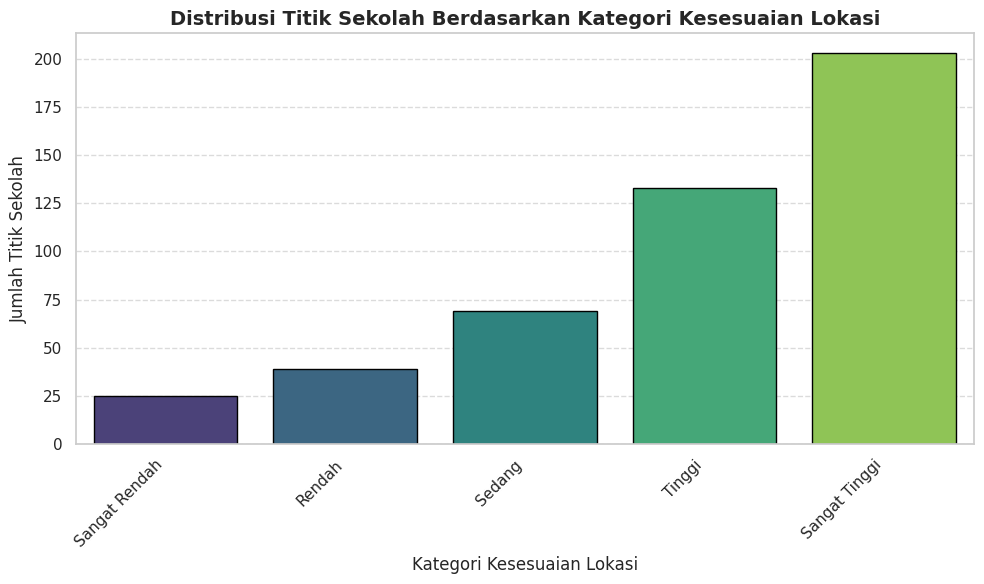


Graph saved to: /content/drive/My Drive/bahan_skripsi/Kesesuaian/output_evaluasi_final/distribusi_sekolah_kesesuaian.png


<Figure size 640x480 with 0 Axes>

In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# --- 1. Load Data ---
# Load the desa suitability GeoDataFrame (from output_mcda)
path_desa_mcda = '/content/drive/My Drive/bahan_skripsi/Kesesuaian/output_mcda/desa_kesesuaian_sma.shp'
gdf_mcda = gpd.read_file(path_desa_mcda)

# Load the existing schools GeoDataFrame
path_sekolah = '/content/drive/My Drive/bahan_skripsi/data/sekolah_eksisting_diy.shp'
gdf_sekolah = gpd.read_file(path_sekolah)

# Ensure both GeoDataFrames have the same CRS for spatial operations
if gdf_mcda.crs != gdf_sekolah.crs:
    gdf_sekolah = gdf_sekolah.to_crs(gdf_mcda.crs)

print(f"Loaded {len(gdf_mcda)} village polygons with suitability categories.")
print(f"Loaded {len(gdf_sekolah)} school points.")

# --- 2. Perform Spatial Join ---
# Join school points with village polygons to get the suitability category for each school
# 'within' predicate means school point must be inside the village polygon
sekolah_dengan_kesesuaian = gpd.sjoin(
    gdf_sekolah, gdf_mcda[['kelas_desa', 'geometry']], how='inner', predicate='within'
)

print(f"After spatial join, {len(sekolah_dengan_kesesuaian)} schools are located within a classified village.")

# --- 3. Analyze Distribution ---
# Count the number of schools in each 'kelas_desa' category
# Ensure class_labels are consistent
class_labels = ['Sangat Rendah', 'Rendah', 'Sedang', 'Tinggi', 'Sangat Tinggi']
distribusi_sekolah = sekolah_dengan_kesesuaian['kelas_desa'].value_counts().reindex(class_labels, fill_value=0)

print("\nDistribution of schools per suitability category:")
print(distribusi_sekolah)

# --- 4. Create the Plot ---
plt.figure(figsize=(10, 6))
sns.barplot(
    x=distribusi_sekolah.index,
    y=distribusi_sekolah.values,
    palette='viridis', # Or RdYlGn_r as used in other cells if consistency is desired
    edgecolor='black'
)

plt.title('Distribusi Titik Sekolah Berdasarkan Kategori Kesesuaian Lokasi',
          fontsize=14, fontweight='bold')
plt.xlabel('Kategori Kesesuaian Lokasi', fontsize=12)
plt.ylabel('Jumlah Titik Sekolah', fontsize=12)
plt.xticks(rotation=45, ha='right') # Rotate labels for better readability
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

output_eval_dir = '/content/drive/My Drive/bahan_skripsi/Kesesuaian/output_evaluasi_final'
os.makedirs(output_eval_dir, exist_ok=True)
plt.savefig(os.path.join(output_eval_dir, 'distribusi_sekolah_kesesuaian.png'), dpi=200, bbox_inches='tight')
print(f"\nGraph saved to: {os.path.join(output_eval_dir, 'distribusi_sekolah_kesesuaian.png')}")

Menghitung AUC untuk WSM, WPM, dan TOPSIS terhadap sekolah eksisting...
Sel dengan sekolah: 390 dari 13162 sel

--- Hasil AUC dan ROC Curve per Metode MCDA ---

Evaluasi untuk Metode: WSM
  Kolom dipakai: skor_wsm | AUC: 0.8307
  Interpretasi: BAIK

Evaluasi untuk Metode: WPM
  Kolom dipakai: skor_wpm | AUC: 0.7911
  Interpretasi: CUKUP

Evaluasi untuk Metode: TOPSIS
  Kolom dipakai: skor_topsi | AUC: 0.8503
  Interpretasi: BAIK

--- Perbandingan AUC Antar Metode ---
  TOPSIS: 0.8503
  WSM: 0.8307
  WPM: 0.7911


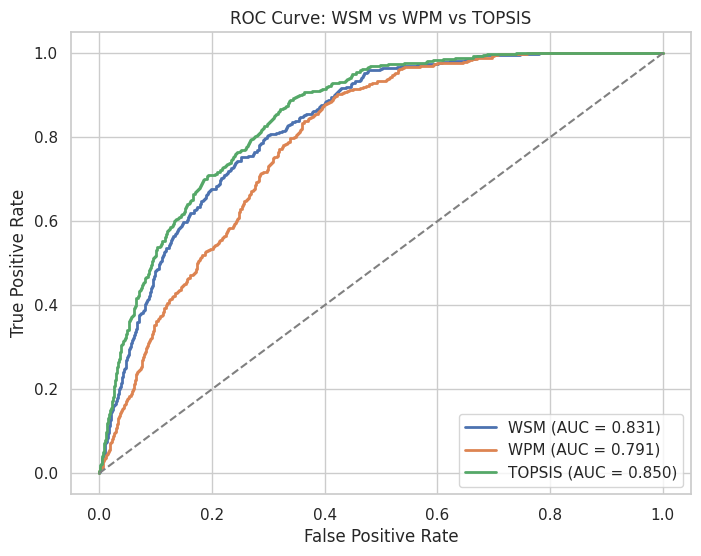

In [ ]:
import os
import numpy as np
import pandas as pd
import geopandas as gpd
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt

print("Menghitung AUC untuk WSM, WPM, dan TOPSIS terhadap sekolah eksisting...")

# --- 1. Muat data ---
path_grid_mcda = '/content/drive/My Drive/bahan_skripsi/Kesesuaian/output_mcda/grid_kesesuaian_sma.shp'
path_sekolah   = '/content/drive/My Drive/bahan_skripsi/data/sekolah_eksisting_diy.shp'

gdf_grid    = gpd.read_file(path_grid_mcda)
gdf_sekolah = gpd.read_file(path_sekolah)

if gdf_grid.crs != gdf_sekolah.crs:
    gdf_sekolah = gdf_sekolah.to_crs(gdf_grid.crs)

# Shapefile memotong nama kolom > 10 karakter (skor_topsis -> skor_topsi)
def resolve_col(gdf, name):
    if name in gdf.columns:
        return name
    if name[:10] in gdf.columns:
        return name[:10]
    raise KeyError(f"Kolom '{name}' tidak ditemukan. Kolom tersedia: {list(gdf.columns)}")

# --- 2. Label sel: 1 jika ada >= 1 sekolah ---
gdf_grid = gdf_grid.reset_index(drop=True)
join = gpd.sjoin(gdf_sekolah[['geometry']], gdf_grid[['geometry']],
                 how='inner', predicate='within')
gdf_grid['school_present'] = gdf_grid.index.isin(join['index_right']).astype(int)
print(f"Sel dengan sekolah: {gdf_grid['school_present'].sum()} dari {len(gdf_grid)} sel")

# --- 3. Evaluasi tiap metode ---
method_names = {'skor_wsm': 'WSM', 'skor_wpm': 'WPM', 'skor_topsis': 'TOPSIS'}
auc_results, roc_data = {}, {}

output_eval_dir = '/content/drive/My Drive/bahan_skripsi/Kesesuaian/output_evaluasi_final'
os.makedirs(output_eval_dir, exist_ok=True)

print("\n--- Hasil AUC dan ROC Curve per Metode MCDA ---")
for score_col, method_name in method_names.items():
    print(f"\nEvaluasi untuk Metode: {method_name}")
    try:
        col = resolve_col(gdf_grid, score_col)
    except KeyError as e:
        print(f"[!] {e}")
        continue

    df_eval = gdf_grid[['school_present', col]].copy()
    df_eval[col] = pd.to_numeric(df_eval[col], errors='coerce')
    df_eval = df_eval.replace([np.inf, -np.inf], np.nan).dropna()

    if df_eval['school_present'].nunique() < 2:
        print(f"[!] Label hanya satu kelas untuk {method_name}, AUC tidak dapat dihitung.")
        continue

    y_true, y_scores = df_eval['school_present'], df_eval[col]
    auc_score = roc_auc_score(y_true, y_scores)
    auc_results[method_name] = auc_score
    print(f"  Kolom dipakai: {col} | AUC: {auc_score:.4f}")

    if auc_score >= 0.9:   print("  Interpretasi: SANGAT BAIK")
    elif auc_score >= 0.8: print("  Interpretasi: BAIK")
    elif auc_score >= 0.7: print("  Interpretasi: CUKUP")
    elif auc_score >= 0.6: print("  Interpretasi: LEMAH")
    else:                  print("  Interpretasi: tidak berguna (cek arah cost/benefit bila < 0,5)")

    fpr, tpr, _ = roc_curve(y_true, y_scores)
    roc_data[method_name] = (fpr, tpr, auc_score)

    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC (AUC = {auc_score:.3f})')
    plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
    plt.xlim([0, 1]); plt.ylim([0, 1.05])
    plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
    plt.title(f'ROC Curve - {method_name}')
    plt.legend(loc='lower right'); plt.grid(True)
    plt.savefig(os.path.join(output_eval_dir, f'roc_curve_{method_name.lower()}_schools.png'),
                dpi=200, bbox_inches='tight')
    plt.close()

# --- 4. Perbandingan ---
print("\n--- Perbandingan AUC Antar Metode ---")
for m, a in sorted(auc_results.items(), key=lambda x: x[1], reverse=True):
    print(f"  {m}: {a:.4f}")

# Satu gambar gabungan
if roc_data:
    plt.figure(figsize=(8, 6))
    for m, (fpr, tpr, a) in roc_data.items():
        plt.plot(fpr, tpr, lw=2, label=f'{m} (AUC = {a:.3f})')
    plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
    plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
    plt.title('ROC Curve: WSM vs WPM vs TOPSIS')
    plt.legend(loc='lower right'); plt.grid(True)
    plt.savefig(os.path.join(output_eval_dir, 'roc_curve_gabungan.png'),
                dpi=200, bbox_inches='tight')
    plt.show()

# Peta Persebaran Sekolah

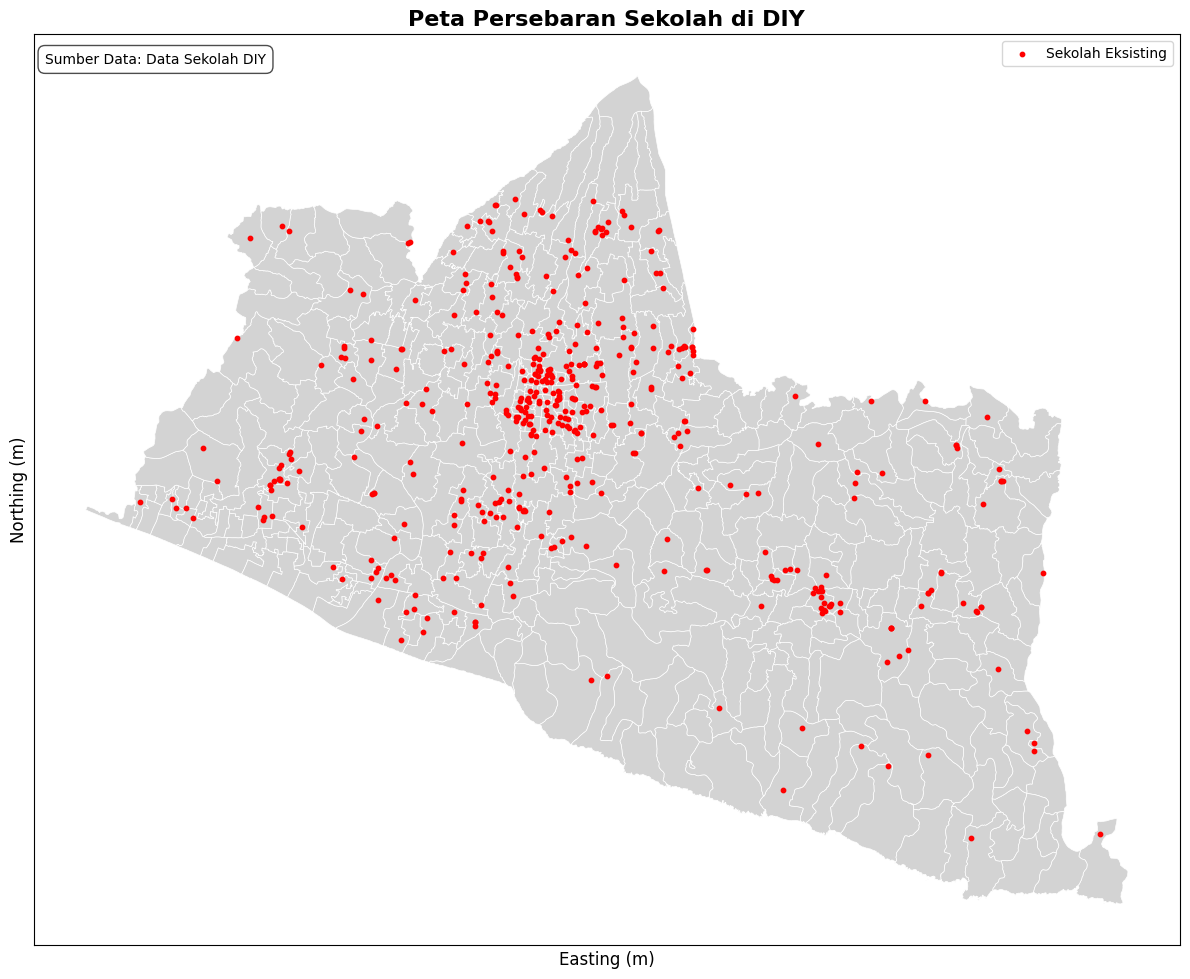

Peta persebaran sekolah berhasil disimpan di: /content/drive/My Drive/bahan_skripsi/Kesesuaian/output_maps/peta_persebaran_sekolah_diy.png


In [ ]:
import matplotlib.pyplot as plt
import geopandas as gpd
import os


path_sekolah = '/content/drive/My Drive/bahan_skripsi/data/sekolah_eksisting_diy.shp'
path_desa_mcda = '/content/drive/My Drive/bahan_skripsi/Kesesuaian/output_mcda/desa_kesesuaian_sma.shp'
gdf_sekolah = gpd.read_file(path_sekolah)
gdf_mcda = gpd.read_file(path_desa_mcda)

if gdf_sekolah.crs != gdf_mcda.crs:
    gdf_sekolah = gdf_sekolah.to_crs(gdf_mcda.crs)

fig, ax = plt.subplots(figsize=(12, 10))

gdf_mcda.plot(ax=ax, color='lightgray', edgecolor='white', linewidth=0.5)

gdf_sekolah.plot(ax=ax, marker='o', color='red', markersize=10, label='Sekolah Eksisting')

ax.set_title('Peta Persebaran Sekolah di DIY', fontsize=16, fontweight='bold')
ax.set_xlabel('Easting (m)', fontsize=12)
ax.set_ylabel('Northing (m)', fontsize=12)

ax.set_xticks([])
ax.set_yticks([])

ax.legend(loc='upper right')

ax.text(0.01, 0.98, 'Sumber Data: Data Sekolah DIY', transform=ax.transAxes,
        fontsize=10, verticalalignment='top', bbox=dict(boxstyle='round,pad=0.5', fc='white', alpha=0.7))

plt.tight_layout()

output_map_dir = '/content/drive/My Drive/bahan_skripsi/Kesesuaian/output_maps'
os.makedirs(output_map_dir, exist_ok=True)
output_map_path = os.path.join(output_map_dir, 'peta_persebaran_sekolah_diy.png')

plt.savefig(output_map_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"Peta persebaran sekolah berhasil disimpan di: {output_map_path}")

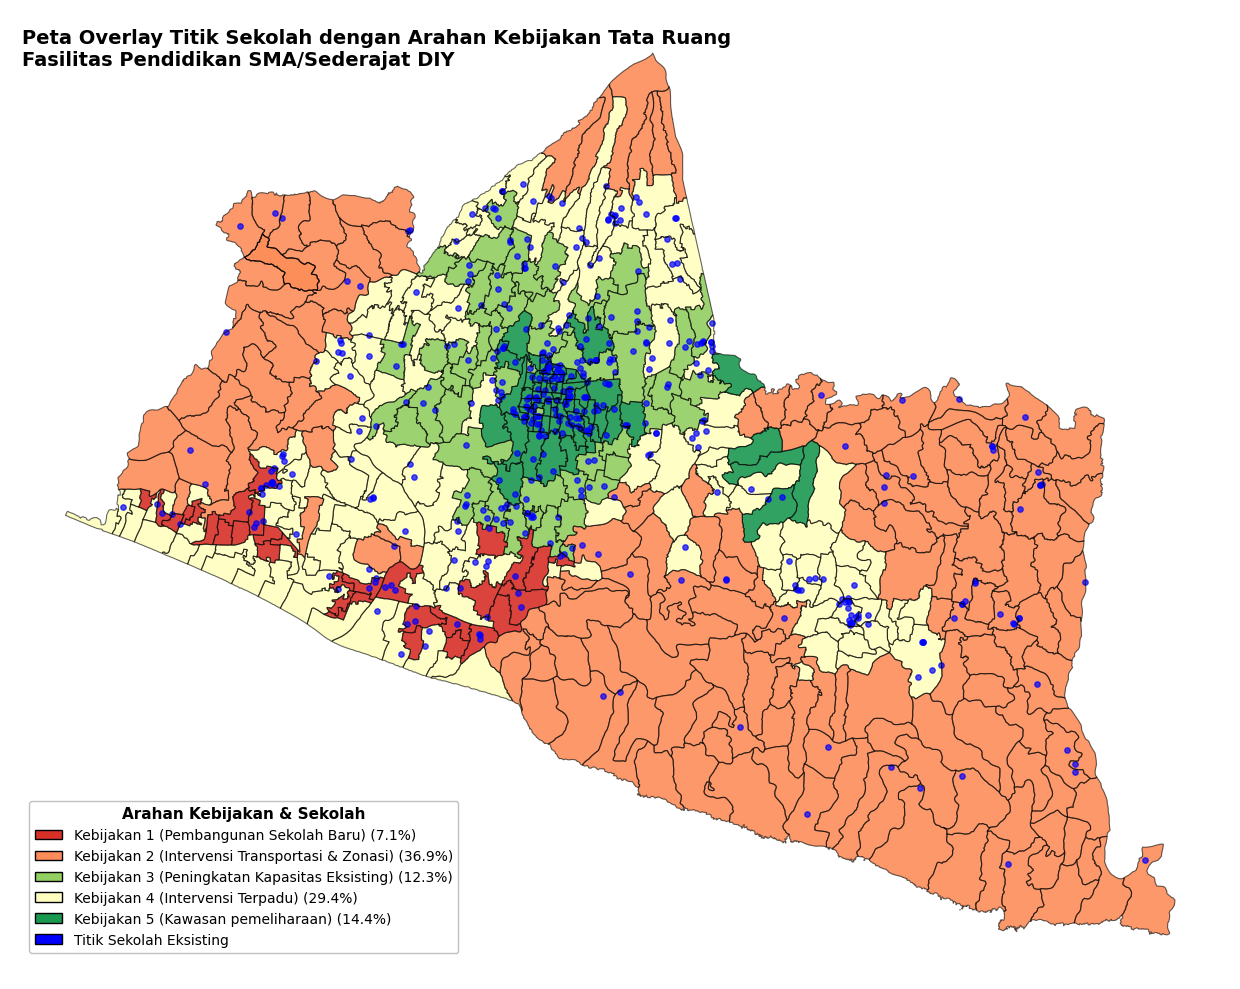

Peta overlay berhasil disimpan di: /content/drive/My Drive/bahan_skripsi/Kesesuaian/output_overlay/peta_overlay_sekolah_kebijakan.png


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import os

# Pastikan gdf_sekolah dan gdf_overlay sudah dimuat

# Memuat ulang gdf_sekolah jika belum ada di lingkungan
if 'gdf_sekolah' not in locals() or gdf_sekolah is None:
    path_sekolah = '/content/drive/My Drive/bahan_skripsi/data/sekolah_eksisting_diy.shp'
    gdf_sekolah = gpd.read_file(path_sekolah)
    if gdf_sekolah.crs is None or gdf_sekolah.crs.to_epsg() != 32749:
        gdf_sekolah.to_crs(epsg=32749, inplace=True)

# Memuat ulang gdf_overlay jika belum ada di lingkungan
if 'gdf_overlay' not in locals() or gdf_overlay is None:
    path_overlay_shp = '/content/drive/My Drive/bahan_skripsi/Kesesuaian/output_overlay/Kebijakan_Lokasi_SMA_Desa.shp'
    gdf_overlay = gpd.read_file(path_overlay_shp)

# Pastikan CRS konsisten untuk plotting
if gdf_sekolah.crs != gdf_overlay.crs:
    gdf_sekolah = gdf_sekolah.to_crs(gdf_overlay.crs)

# Definisikan kembali color_map dan urutan_kebijakan untuk konsistensi legenda
KEB1 = 'Kebijakan 1 (Pembangunan Sekolah Baru)'
KEB2 = 'Kebijakan 2 (Intervensi Transportasi & Zonasi)'
KEB3 = 'Kebijakan 3 (Peningkatan Kapasitas Eksisting)'
KEB4 = 'Kebijakan 4 (Intervensi Terpadu)'
KEB5 = 'Kebijakan 5 (Kawasan pemeliharaan)'
TIDAK_ADA_DATA = 'Tidak Ada Data'

color_map = {
    KEB1           : '#d73027',  # Merah (Sangat Mendesak untuk dibangun)
    KEB2           : '#fc8d59',  # Oranye (Mendesak tapi rekayasa rute)
    KEB3           : '#91cf60',  # Hijau Tua (Sudah baik, cukup dioptimalkan)
    KEB4           : '#ffffbf',  # Kuning (Pantau / transisi)
    KEB5           : '#1a9850',  # Hijau Muda (Batas aman, jangan dibangun)
    TIDAK_ADA_DATA : '#cccccc',  # Abu-abu
}

urutan_kebijakan = [KEB1, KEB2, KEB3, KEB4, KEB5, TIDAK_ADA_DATA]

# --- Buat plot ---
fig, ax = plt.subplots(figsize=(14, 10), facecolor='white')
ax.set_facecolor('white')

# Plot hasil kebijakan (gdf_overlay)
for kebijakan, color in color_map.items():
    sub_gdf = gdf_overlay[gdf_overlay['Kebijakan'] == kebijakan]
    if not sub_gdf.empty:
        sub_gdf.plot(ax=ax, color=color, edgecolor='none', alpha=0.9)

# Plot batas desa untuk konteks
gdf_overlay.boundary.plot(ax=ax, color='black', linewidth=0.8, alpha=0.6)

# Plot titik-titik sekolah
gdf_sekolah.plot(ax=ax, marker='o', color='blue', markersize=15, alpha=0.7, label='Titik Sekolah Eksisting')

# Hapus garis sumbu dan koordinat X/Y
ax.set_axis_off()

# Letakkan judul di pojok kiri atas
ax.text(0.01, 0.98,
        'Peta Overlay Titik Sekolah dengan Arahan Kebijakan Tata Ruang\nFasilitas Pendidikan SMA/Sederajat DIY',
        transform=ax.transAxes,
        fontsize=14, fontweight='bold', va='top', ha='left')

# Letakkan legenda di pojok kiri bawah
legend_patches = []
# Tambahkan legenda untuk kebijakan
for p in urutan_kebijakan:
    jumlah = (gdf_overlay['Kebijakan'] == p).sum()
    if jumlah > 0:
        persen = jumlah / len(gdf_overlay) * 100
        label_text = f"{p} ({persen:.1f}%)"
        legend_patches.append(mpatches.Patch(facecolor=color_map[p], edgecolor='black', linewidth=1, label=label_text))

# Tambahkan legenda untuk titik sekolah secara terpisah
legend_patches.append(mpatches.Patch(facecolor='blue', edgecolor='black', linewidth=1, label='Titik Sekolah Eksisting'))

leg = ax.legend(handles=legend_patches, title='Arahan Kebijakan & Sekolah',
                loc='lower left', fontsize=10, title_fontsize=11,
                frameon=True, facecolor='white', framealpha=1, edgecolor='silver',
                bbox_to_anchor=(0.01, 0.02))
plt.setp(leg.get_title(), fontweight='bold')

plt.tight_layout()

# Definisikan direktori output dan nama file
output_overlay_dir = '/content/drive/My Drive/bahan_skripsi/Kesesuaian/output_overlay'
os.makedirs(output_overlay_dir, exist_ok=True)
output_map_path = os.path.join(output_overlay_dir, 'peta_overlay_sekolah_kebijakan.png')

# Simpan peta
plt.savefig(output_map_path, dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

print(f"Peta overlay berhasil disimpan di: {output_map_path}")